# UPI Fraud Detection — End-to-End Notebook

**Phases covered:** 1 EDA → 2 Preprocessing → 3 Feature engineering → 4 Model development → 5 Evaluation → 6 Fraud-monitoring dashboard (Streamlit + Plotly).

**How to run**
1. Set `DATA_PATH` in the configuration cell (default: `/content/drive/MyDrive/Manthan/upi_transactions.csv`).
2. Run all cells top to bottom. Phase 6 saves artifacts to `artifacts/` and writes `app.py`.
3. Launch the dashboard: `streamlit run app.py`.

**Design principles**
- **No silent fallbacks.** If the CSV is missing, the notebook stops. It never substitutes fake data.
- **No leakage.** Splits are chronological. Anything learned from data (scaler, encoder, imputer, "high-value" threshold) is fit on the training split only. Engineered behavioural features only look backwards in time.
- **Honest evaluation.** Fraud is rare, so the primary metric is PR-AUC (baseline = fraud prevalence), reported with bootstrap confidence intervals on the held-out test set. Raw accuracy is never used.
- **Features must earn their place.** Each engineered feature is tested against a noise estimate before it is kept.

In [1]:
# Colab usually has most of these; the install is quick and safe to re-run.
%pip install -q xgboost imbalanced-learn plotly streamlit

In [2]:
import os, sys, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve, roc_curve)
from xgboost import XGBClassifier
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ----------------------------- CONFIGURATION -----------------------------
DATA_PATH     = "/content/drive/MyDrive/Manthan/upi_transactions.csv"
ARTIFACT_DIR  = "artifacts"
RANDOM_STATE  = 42
TARGET        = "is_fraud"        # the raw column `fraud_flag` is renamed to this
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15  # remaining 0.15 is the test set
# Only for smoke-testing the notebook with schema-matched FAKE data (set env var UPI_DEMO=1).
# Never use for real results: the notebook prints a loud warning when this is on.
USE_DEMO_DATA = os.environ.get("UPI_DEMO") == "1"
# -------------------------------------------------------------------------
os.makedirs(ARTIFACT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

In [3]:
def make_demo_data(n=250_000, seed=0):
    """Schema-matched FAKE data, only used when USE_DEMO_DATA is True."""
    rng = np.random.default_rng(seed)
    ts = pd.Timestamp("2024-01-01") + pd.to_timedelta(rng.integers(0, 366 * 24 * 3600, n), unit="s")
    d = pd.DataFrame({
        "transaction id": [f"TXN{i:010d}" for i in range(1, n + 1)],
        "timestamp": ts,
        "transaction type": rng.choice(["P2P", "P2M", "Bill Payment", "Recharge"], n, p=[.45, .35, .12, .08]),
        "merchant_category": rng.choice(["Grocery", "Fuel", "Shopping", "Entertainment", "Food", "Utilities", "Transport"], n),
        "amount (INR)": np.clip(rng.lognormal(6.4, 1.0, n), 1, 100000).astype(int),
        "transaction_status": rng.choice(["SUCCESS", "FAILED"], n, p=[.95, .05]),
        "sender_age_group": rng.choice(["18-25", "26-35", "36-45", "46-55", "56+"], n, p=[.2, .4, .22, .12, .06]),
        "receiver_age_group": rng.choice(["18-25", "26-35", "36-45", "46-55", "56+"], n, p=[.2, .4, .22, .12, .06]),
        "sender_state": rng.choice(["Delhi", "Maharashtra", "Karnataka", "Uttar Pradesh", "Tamil Nadu", "Gujarat",
                                    "Telangana", "West Bengal", "Rajasthan", "Andhra Pradesh"], n),
        "sender_bank": rng.choice(["SBI", "HDFC", "ICICI", "Axis", "PNB", "Yes Bank", "Kotak", "IndusInd"], n),
        "receiver_bank": rng.choice(["SBI", "HDFC", "ICICI", "Axis", "PNB", "Yes Bank", "Kotak", "IndusInd"], n),
        "device_type": rng.choice(["Android", "iOS", "Web"], n, p=[.72, .24, .04]),
        "network_type": rng.choice(["4G", "5G", "WiFi", "3G"], n, p=[.5, .2, .27, .03]),
    })
    d["timestamp"] = d["timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S")
    h = pd.to_datetime(d["timestamp"]).dt.hour
    p = 0.0018 + 0.002 * ((h >= 23) | (h <= 4)) + 0.002 * (d["amount (INR)"] > 3000)
    d["fraud_flag"] = (rng.random(n) < p).astype(int)
    d["hour_of_day"] = h
    d["day_of_week"] = pd.to_datetime(d["timestamp"]).dt.day_name()
    d["is_weekend"] = pd.to_datetime(d["timestamp"]).dt.dayofweek.isin([5, 6]).astype(int)
    return d

if USE_DEMO_DATA:
    print("!" * 78, "\n!!  DEMO MODE: using FAKE schema-matched data. Do NOT report these results.  !!\n" + "!" * 78)
    raw = make_demo_data()
else:
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
    candidates = [DATA_PATH, "upi_transactions.csv", os.path.join("data", "upi_transactions.csv")]
    path = next((p for p in candidates if os.path.exists(p)), None)
    if path is None:
        raise FileNotFoundError(f"Dataset not found. Looked in: {candidates}. Fix DATA_PATH in the config cell.")
    raw = pd.read_csv(path)
    print(f"Loaded {path}")

# --- Standardise column names: 'amount (INR)' -> 'amount_inr', 'transaction id' -> 'transaction_id' ---
raw.columns = [re.sub(r"[^0-9a-z]+", "_", c.lower()).strip("_") for c in raw.columns]
raw = raw.rename(columns={"fraud_flag": TARGET})

required = ["transaction_id", "timestamp", "transaction_type", "merchant_category", "amount_inr", "transaction_status",
            "sender_state", "sender_bank", "receiver_bank", "device_type", "network_type", TARGET]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise KeyError(f"Missing expected columns: {missing_cols}. Found: {list(raw.columns)}")

# --- Timestamp-derived columns (single source of truth: the timestamp itself) ---
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw = raw.sort_values("timestamp", kind="stable").reset_index(drop=True)
raw["hour"] = raw["timestamp"].dt.hour
raw["dow"] = raw["timestamp"].dt.dayofweek            # 0 = Monday
raw["day_name"] = raw["timestamp"].dt.day_name()
raw["is_weekend"] = raw["dow"].isin([5, 6]).astype(int)
raw["date"] = raw["timestamp"].dt.floor("D")

# Consistency check against the pre-computed columns shipped with the CSV, then drop them
if "hour_of_day" in raw.columns:
    print("Rows where provided hour_of_day != timestamp hour:", int((raw["hour_of_day"] != raw["hour"]).sum()))
if "day_of_week" in raw.columns:
    print("Rows where provided day_of_week != timestamp day  :", int((raw["day_of_week"].astype(str) != raw["day_name"]).sum()))
raw = raw.drop(columns=[c for c in ["hour_of_day", "day_of_week"] if c in raw.columns])

df = raw.copy()
print(f"\nShape: {df.shape} | date range: {df.timestamp.min()} -> {df.timestamp.max()}")
df.head()

Mounted at /content/drive
Loaded /content/drive/MyDrive/Manthan/upi_transactions.csv
Rows where provided hour_of_day != timestamp hour: 0
Rows where provided day_of_week != timestamp day  : 0

Shape: (250000, 19) | date range: 2024-01-01 00:05:10 -> 2024-12-30 23:55:40


,transaction_id,timestamp,transaction_type,merchant_category,amount_inr,transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,is_fraud,is_weekend,hour,dow,day_name,date
0,TXN0000173177,2024-01-01 00:05:10,P2M,Grocery,1540,SUCCESS,18-25,36-45,Delhi,Axis,Yes Bank,iOS,3G,0,0,0,0,Monday,2024-01-01
1,TXN0000149806,2024-01-01 00:09:26,P2P,Utilities,1438,SUCCESS,26-35,46-55,Uttar Pradesh,Axis,SBI,iOS,4G,0,0,0,0,Monday,2024-01-01
2,TXN0000100282,2024-01-01 00:23:01,P2M,Utilities,394,SUCCESS,36-45,18-25,Telangana,Yes Bank,HDFC,Web,4G,0,0,0,0,Monday,2024-01-01
3,TXN0000184313,2024-01-01 00:25:13,P2P,Shopping,1716,SUCCESS,26-35,46-55,Maharashtra,SBI,Yes Bank,Android,5G,0,0,0,0,Monday,2024-01-01
4,TXN0000218473,2024-01-01 00:29:10,P2P,Shopping,439,SUCCESS,26-35,18-25,West Bengal,Axis,SBI,Android,5G,0,0,0,0,Monday,2024-01-01


---
# Phase 1 — Exploratory Data Analysis (UPI)
Goal: understand the data and find patterns that could help identify fraud. Because fraud is very rare, every fraud-rate bar below carries a **95% Wilson confidence interval** and a dashed line for the overall fraud rate. Differences that fall inside the interval are indistinguishable from noise.

In [4]:
# ---- 1.0 Dataset overview and data quality ----
n_total, n_fraud = len(df), int(df[TARGET].sum())
overall_rate = n_fraud / n_total * 100
print(f"Transactions: {n_total:,} | Fraud: {n_fraud:,} ({overall_rate:.3f}%) | Legit: {n_total - n_fraud:,}")
print(f"Imbalance ratio (legit : fraud) = {(n_total - n_fraud) / max(n_fraud, 1):,.0f} : 1\n")
display(df.dtypes.to_frame("dtype").join(df.nunique().to_frame("n_unique")).join(df.isna().sum().to_frame("n_missing")))
display(df.describe(include="all").T.head(25))

Transactions: 250,000 | Fraud: 480 (0.192%) | Legit: 249,520
Imbalance ratio (legit : fraud) = 520 : 1



,dtype,n_unique,n_missing
transaction_id,object,250000,0
timestamp,datetime64[ns],248610,0
transaction_type,object,4,0
merchant_category,object,10,0
amount_inr,int64,10355,0
transaction_status,object,2,0
sender_age_group,object,5,0
receiver_age_group,object,5,0
sender_state,object,10,0
sender_bank,object,8,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,250000,250000,TXN0000075259,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,250000,NaN,NaN,NaN,2024-07-01 15:57:20.438195712,2024-01-01 00:05:10,2024-04-01 15:12:57.249999872,2024-07-01 14:34:17,2024-09-30 18:13:45,2024-12-30 23:55:40,NaN
transaction_type,250000,4,P2P,112445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,250000,10,Grocery,49966,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_inr,250000.0,NaN,NaN,NaN,1311.756036,10.0,288.0,629.0,1596.0,42099.0,1848.059224
transaction_status,250000,2,SUCCESS,237624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_age_group,250000,5,26-35,87432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
receiver_age_group,250000,5,26-35,87864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_state,250000,10,Maharashtra,37427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_bank,250000,8,SBI,62693,NaN,NaN,NaN,NaN,NaN,NaN,NaN


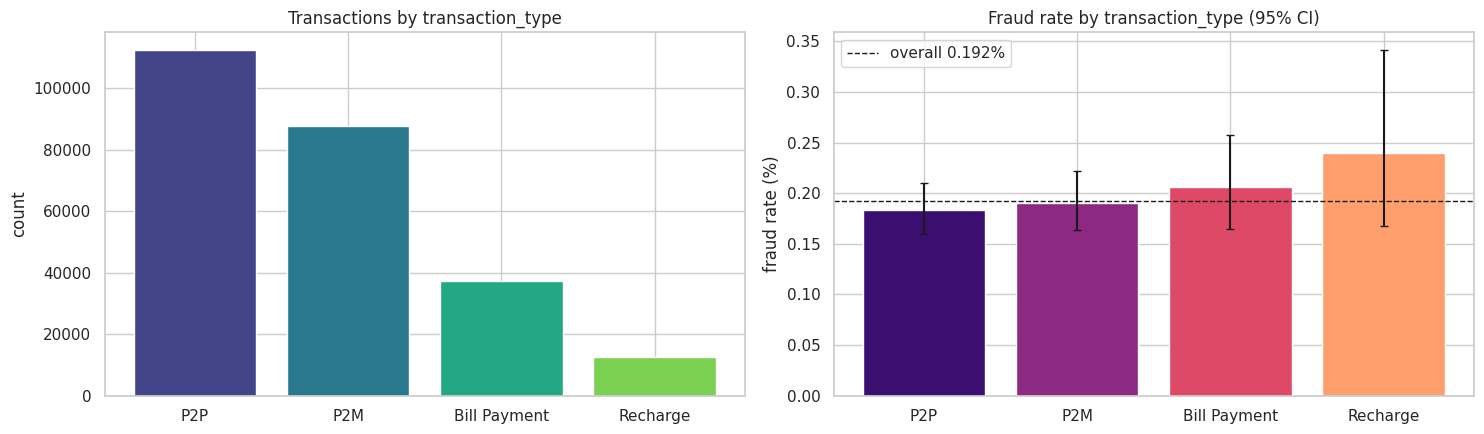

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
transaction_type,,,,,
P2P,112445,206,0.1832,0.1599,0.2100
P2M,87660,167,0.1905,0.1637,0.2216
Bill Payment,37368,77,0.2061,0.1649,0.2574
Recharge,12527,30,0.2395,0.1678,0.3417


In [5]:
# ---- Helpers shared by all EDA cells ----
def wilson_ci(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / np.maximum(n, 1)
    denom = 1 + z**2 / np.maximum(n, 1)
    centre = (p + z**2 / (2 * np.maximum(n, 1))) / denom
    half = z * np.sqrt(p * (1 - p) / np.maximum(n, 1) + z**2 / (4 * np.maximum(n, 1)**2)) / denom
    return (centre - half) * 100, (centre + half) * 100

def fraud_table(data, col, sort=True):
    g = data.groupby(col, observed=True)[TARGET].agg(transactions="size", frauds="sum")
    g["fraud_rate_pct"] = g["frauds"] / g["transactions"] * 100
    g["ci_low"], g["ci_high"] = wilson_ci(g["frauds"], g["transactions"])
    return g.sort_values("fraud_rate_pct", ascending=False) if sort else g

def plot_volume_and_fraud(data, col, order=None, top=None, title=None, rotate=0):
    """Left: transaction volume. Right: fraud rate with Wilson CI and the overall-rate reference line."""
    g = fraud_table(data, col, sort=False)
    g = g.loc[order] if order is not None else g.sort_values("transactions", ascending=False)
    if top: g = g.head(top)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    ax[0].bar(g.index.astype(str), g["transactions"], color=sns.color_palette("viridis", len(g)))
    ax[0].set_title(f"Transactions by {col}"); ax[0].set_ylabel("count")
    err = [g["fraud_rate_pct"] - g["ci_low"], g["ci_high"] - g["fraud_rate_pct"]]
    ax[1].bar(g.index.astype(str), g["fraud_rate_pct"], yerr=err, capsize=3, color=sns.color_palette("magma", len(g)))
    ax[1].axhline(overall_rate, ls="--", c="k", lw=1, label=f"overall {overall_rate:.3f}%")
    ax[1].set_title(title or f"Fraud rate by {col} (95% CI)"); ax[1].set_ylabel("fraud rate (%)"); ax[1].legend()
    for a in ax: a.tick_params(axis="x", rotation=rotate)
    plt.tight_layout(); plt.show()
    return g

# ---- 1.1 Transaction type distribution & 1.2 Fraud by transaction type ----
g = plot_volume_and_fraud(df, "transaction_type")
display(g.round(4))

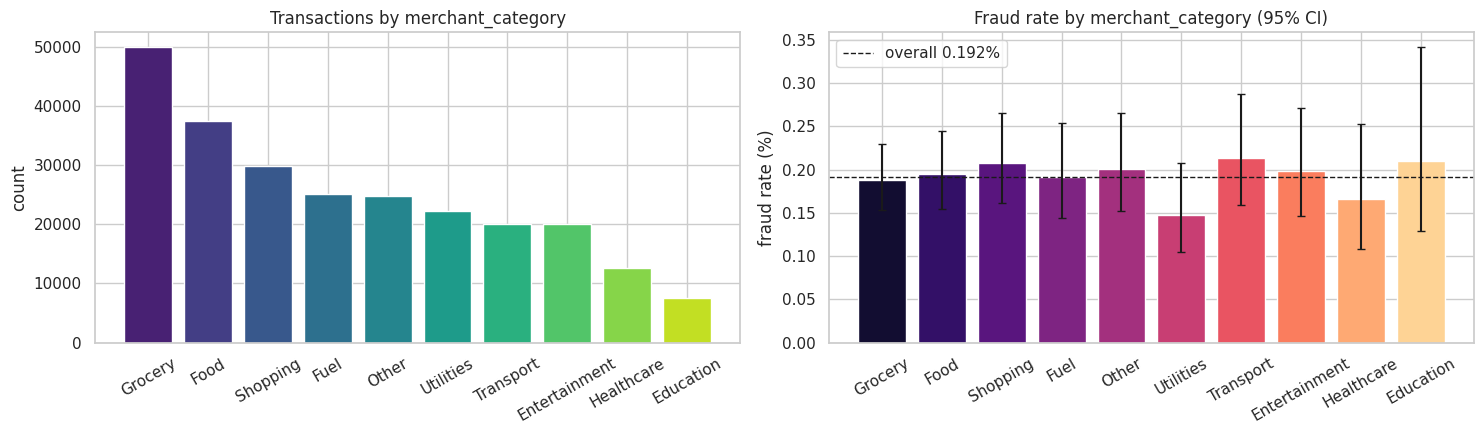

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
merchant_category,,,,,
Grocery,49966,94,0.1881,0.1538,0.2301
Food,37464,73,0.1949,0.1550,0.2449
Shopping,29872,62,0.2076,0.1620,0.2660
Fuel,25063,48,0.1915,0.1445,0.2538
Other,24828,50,0.2014,0.1528,0.2654
Utilities,22338,33,0.1477,0.1052,0.2074
Transport,20105,43,0.2139,0.1588,0.2879
Entertainment,20103,40,0.1990,0.1462,0.2708
Healthcare,12663,21,0.1658,0.1085,0.2534


In [6]:
# ---- 1.3 Fraud by merchant category ----
g = plot_volume_and_fraud(df, "merchant_category", rotate=30)
display(g.round(4))

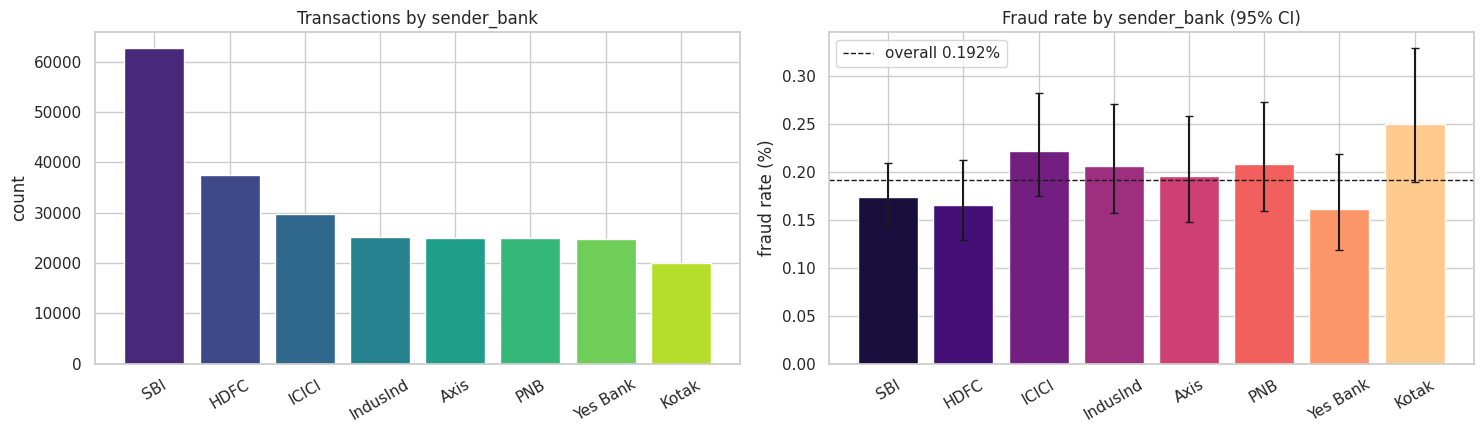

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
sender_bank,,,,,
SBI,62693,109,0.1739,0.1442,0.2097
HDFC,37485,62,0.1654,0.1291,0.2120
ICICI,29769,66,0.2217,0.1743,0.2819
IndusInd,25173,52,0.2066,0.1576,0.2708
Axis,25042,49,0.1957,0.1480,0.2586
PNB,24946,52,0.2085,0.1590,0.2732
Yes Bank,24860,40,0.1609,0.1182,0.2190
Kotak,20032,50,0.2496,0.1894,0.3289


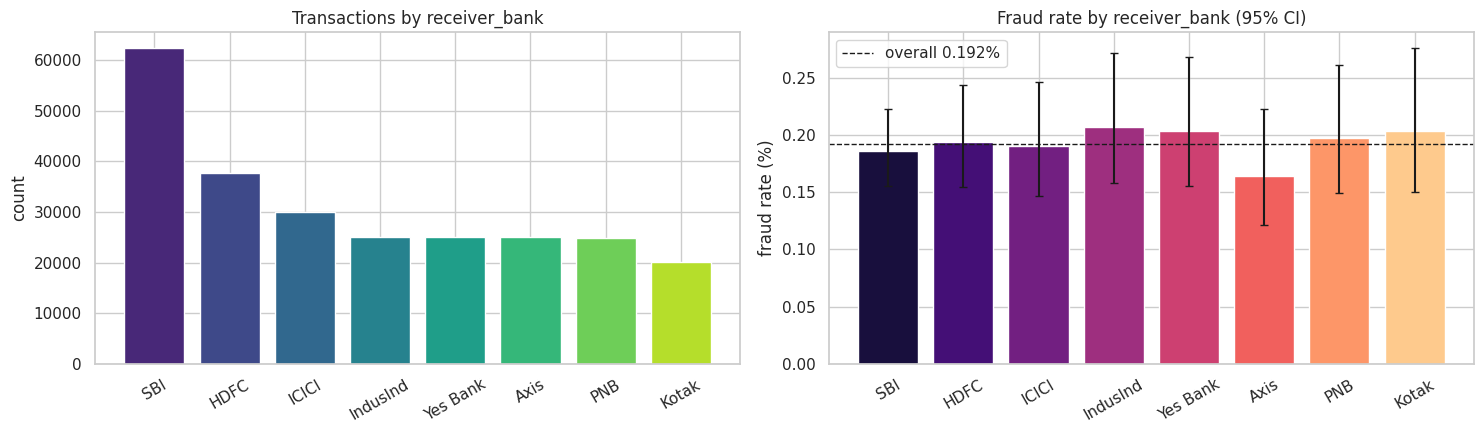

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
receiver_bank,,,,,
SBI,62378,116,0.1860,0.1551,0.2230
HDFC,37651,73,0.1939,0.1542,0.2437
ICICI,29944,57,0.1904,0.1470,0.2465
IndusInd,25086,52,0.2073,0.1581,0.2717
Yes Bank,25009,51,0.2039,0.1551,0.2680
Axis,24992,41,0.1641,0.1210,0.2225
PNB,24802,49,0.1976,0.1495,0.2611
Kotak,20138,41,0.2036,0.1501,0.2761


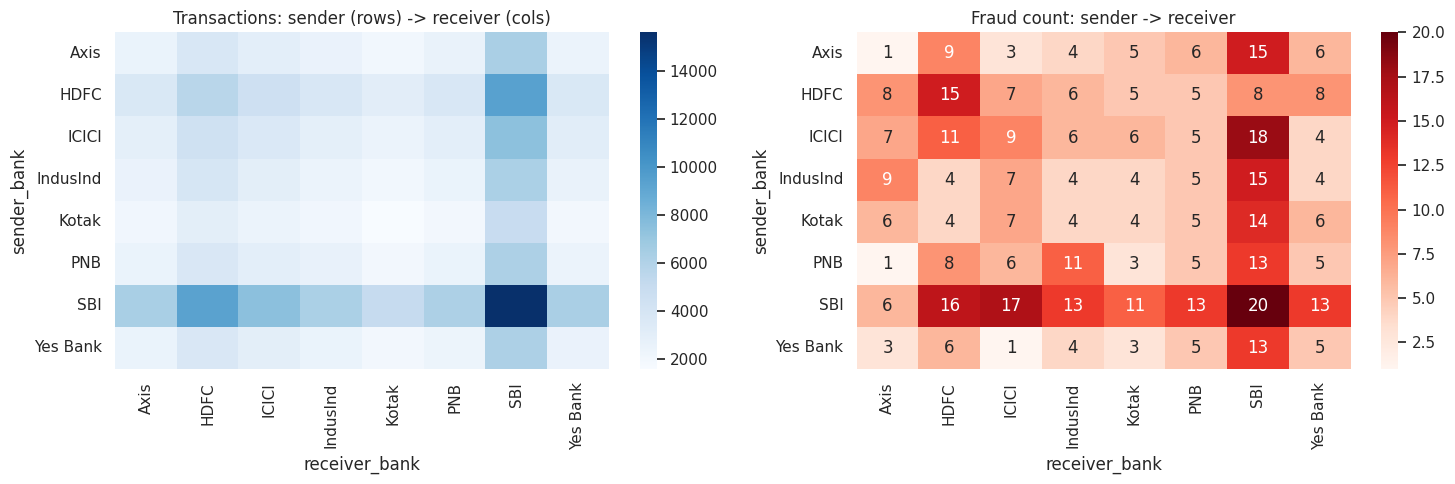

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
_cross_bank,,,,,
cross bank,213679,417,0.1952,0.1773,0.2148
same bank,36321,63,0.1735,0.1356,0.2218


In [7]:
# ---- 1.4 Fraud by sender and receiver banks ----
for col in ["sender_bank", "receiver_bank"]:
    g = plot_volume_and_fraud(df, col, rotate=30)
    display(g.round(4))

# Bank-to-bank view: fraud counts (rates are too noisy at this granularity, so show counts + volume)
pair = df.groupby(["sender_bank", "receiver_bank"])[TARGET].agg(["size", "sum"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(pair["size"].unstack(), cmap="Blues", ax=ax[0], annot=False); ax[0].set_title("Transactions: sender (rows) -> receiver (cols)")
sns.heatmap(pair["sum"].unstack(), cmap="Reds", ax=ax[1], annot=True, fmt="d"); ax[1].set_title("Fraud count: sender -> receiver")
plt.tight_layout(); plt.show()

df["_cross_bank"] = (df["sender_bank"] != df["receiver_bank"]).astype(int)
display(fraud_table(df, "_cross_bank").rename(index={0: "same bank", 1: "cross bank"}).round(4))
df = df.drop(columns="_cross_bank")

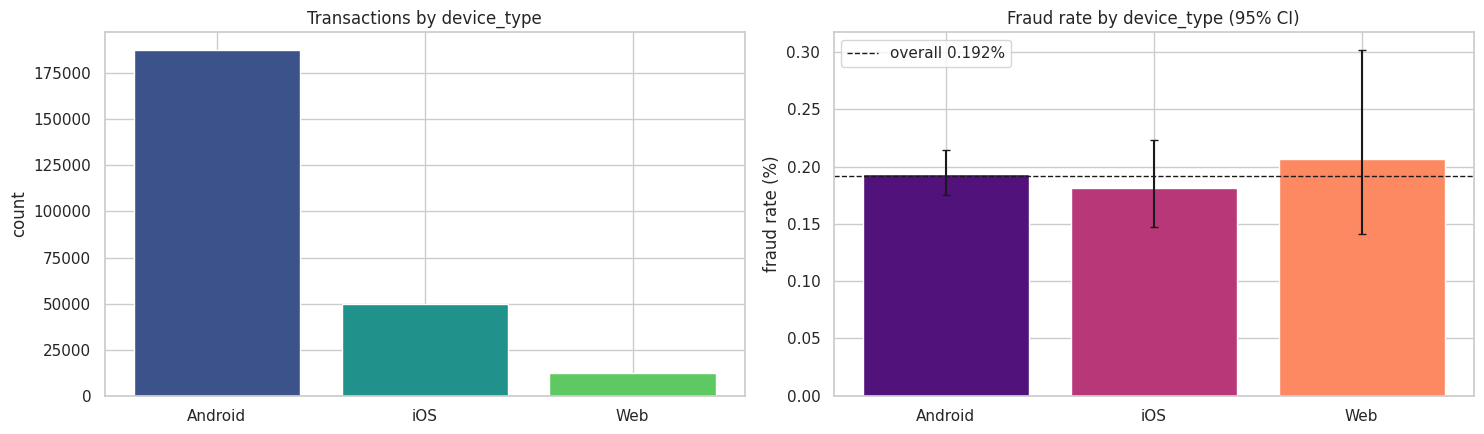

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
device_type,,,,,
Android,187777,364,0.1938,0.1749,0.2148
iOS,49613,90,0.1814,0.1476,0.2229
Web,12610,26,0.2062,0.1407,0.3020


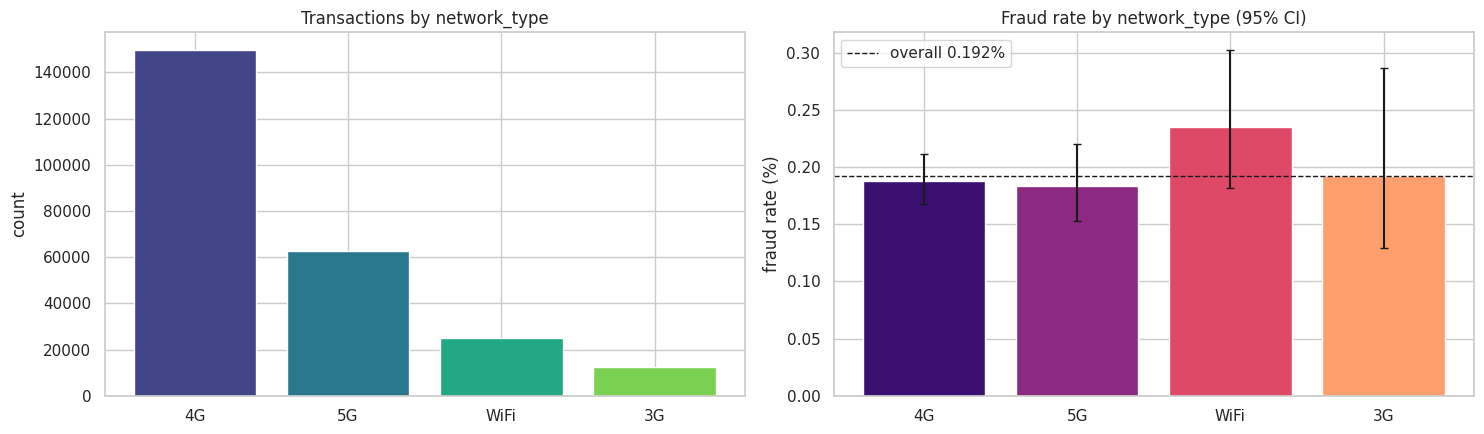

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
network_type,,,,,
4G,149813,282,0.1882,0.1675,0.2115
5G,62582,115,0.1838,0.1531,0.2205
WiFi,25134,59,0.2347,0.1820,0.3027
3G,12471,24,0.1924,0.1294,0.2862


In [8]:
# ---- 1.5 Fraud by device and network ----
for col in ["device_type", "network_type"]:
    g = plot_volume_and_fraud(df, col)
    display(g.round(4))

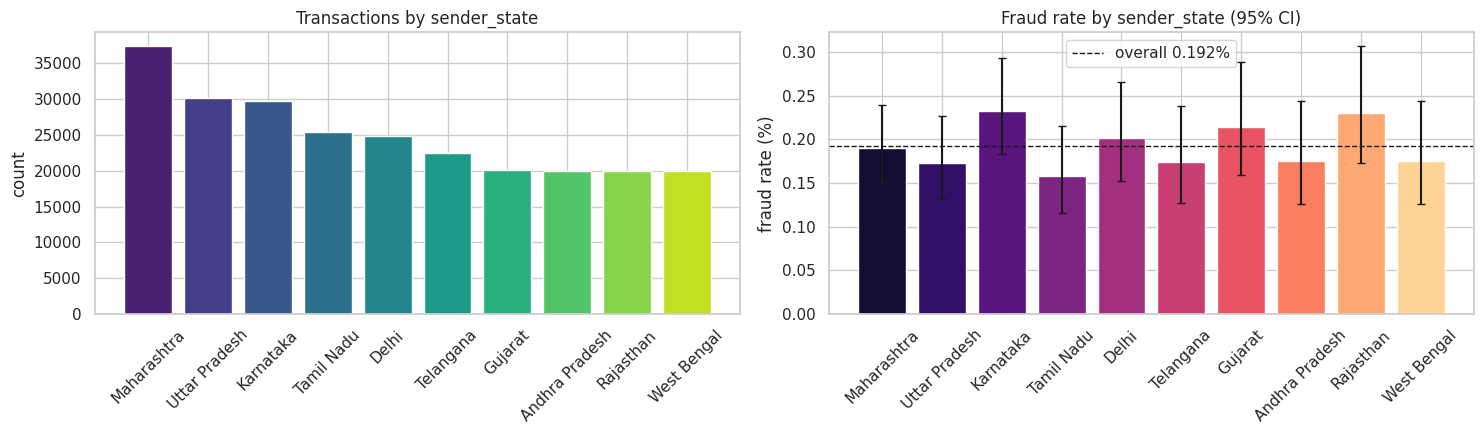

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
sender_state,,,,,
Maharashtra,37427,71,0.1897,0.1504,0.2392
Uttar Pradesh,30125,52,0.1726,0.1317,0.2263
Karnataka,29756,69,0.2319,0.1833,0.2933
Tamil Nadu,25367,40,0.1577,0.1158,0.2146
Delhi,24870,50,0.2010,0.1525,0.2649
Telangana,22435,39,0.1738,0.1272,0.2375
Gujarat,20061,43,0.2143,0.1592,0.2886
Andhra Pradesh,20006,35,0.1749,0.1258,0.2432
Rajasthan,19981,46,0.2302,0.1727,0.3069


In [9]:
# ---- 1.6 Fraud by state ----
g = plot_volume_and_fraud(df, "sender_state", rotate=45)
display(g.round(4))

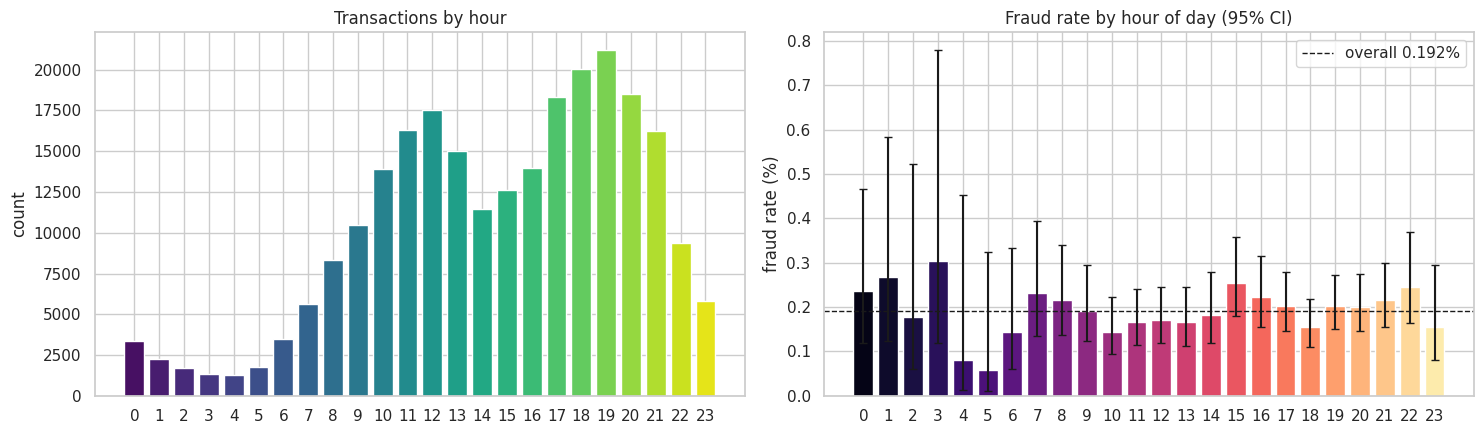

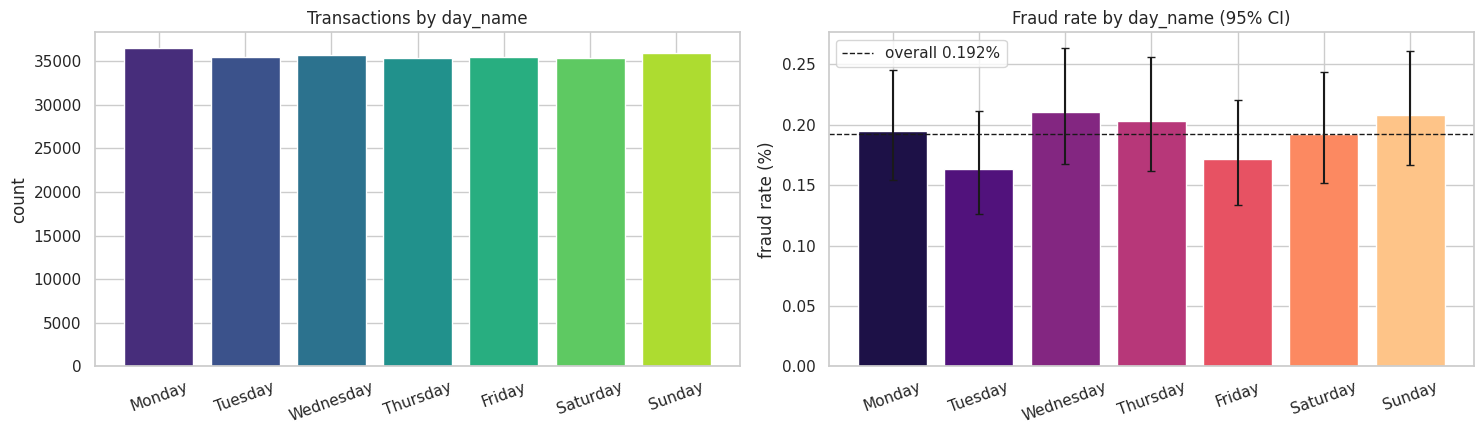

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
day_name,,,,,
Monday,36495,71,0.1945,0.1543,0.2453
Tuesday,35540,58,0.1632,0.1263,0.2109
Wednesday,35700,75,0.2101,0.1676,0.2632
Thursday,35432,72,0.2032,0.1614,0.2558
Friday,35496,61,0.1719,0.1338,0.2207
Saturday,35334,68,0.1924,0.1518,0.2439
Sunday,36003,75,0.2083,0.1662,0.2610


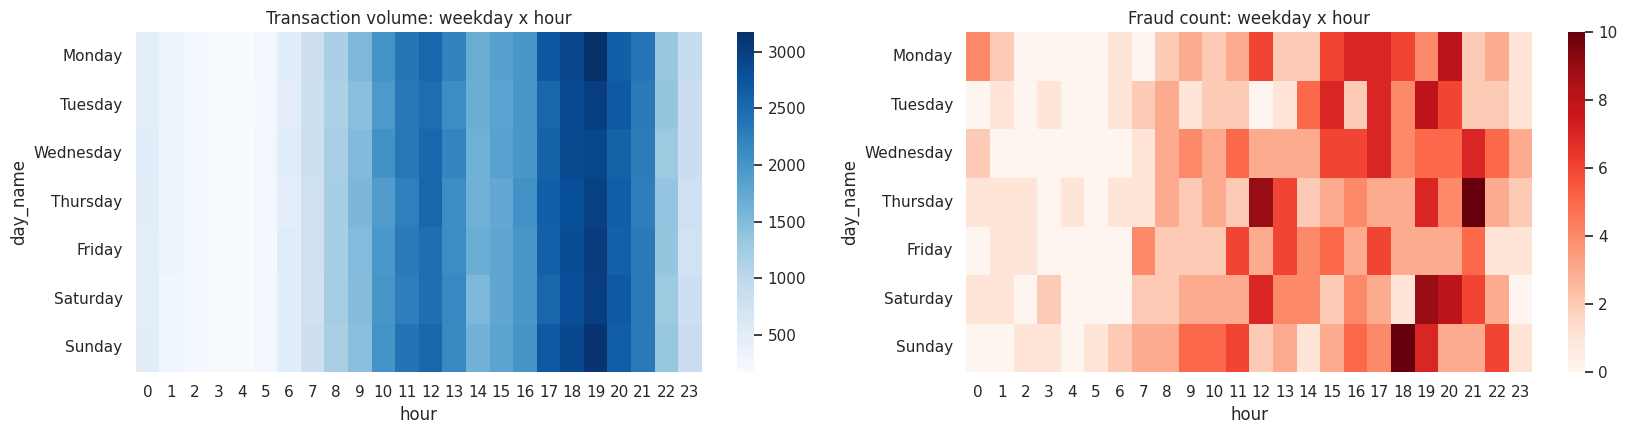

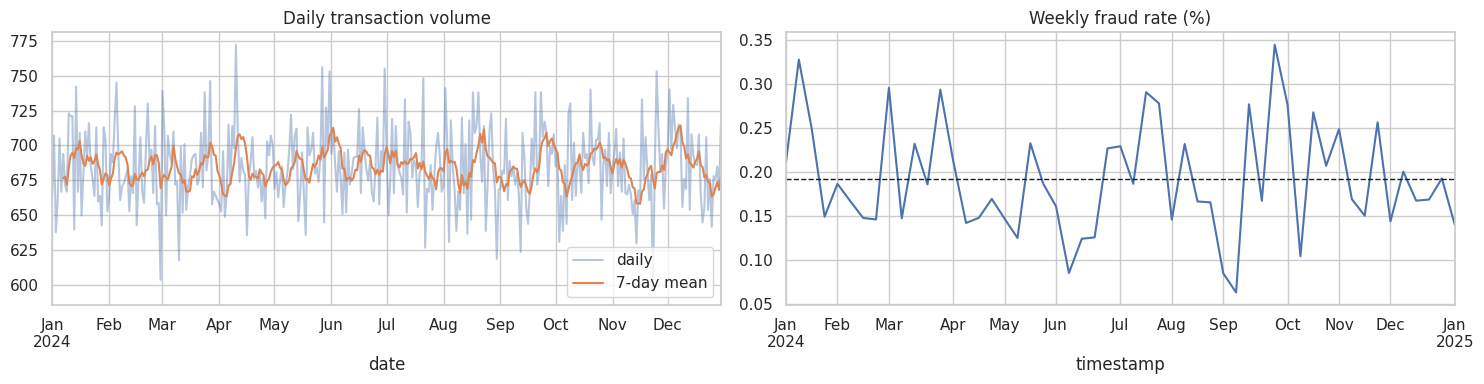

In [10]:
# ---- 1.7 Hourly and daily transaction patterns ----
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
plot_volume_and_fraud(df, "hour", order=sorted(df["hour"].unique()), title="Fraud rate by hour of day (95% CI)")
g = plot_volume_and_fraud(df, "day_name", order=dow_order, rotate=20)
display(g.loc[dow_order].round(4))

# Hour x weekday heatmaps
vol = df.pivot_table(index="day_name", columns="hour", values=TARGET, aggfunc="size").reindex(dow_order)
frd = df.pivot_table(index="day_name", columns="hour", values=TARGET, aggfunc="sum").reindex(dow_order)
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
sns.heatmap(vol, cmap="Blues", ax=ax[0]); ax[0].set_title("Transaction volume: weekday x hour")
sns.heatmap(frd, cmap="Reds", ax=ax[1]); ax[1].set_title("Fraud count: weekday x hour")
plt.tight_layout(); plt.show()

# Daily / weekly trend
daily = df.groupby("date")[TARGET].agg(["size", "sum"])
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
daily["size"].plot(ax=ax[0], alpha=.4, label="daily"); daily["size"].rolling(7).mean().plot(ax=ax[0], label="7-day mean")
ax[0].set_title("Daily transaction volume"); ax[0].legend()
wk = df.set_index("timestamp")[TARGET].resample("W").agg(["sum", "size"])
(wk["sum"] / wk["size"] * 100).plot(ax=ax[1]); ax[1].axhline(overall_rate, ls="--", c="k", lw=1)
ax[1].set_title("Weekly fraud rate (%)")
plt.tight_layout(); plt.show()

             count     mean      std   min    25%    50%     75%      max
is_fraud                                                                 
0         249520.0  1311.40  1847.21  10.0  288.0  629.0  1596.0  42099.0
1            480.0  1499.23  2240.71  28.0  260.0  618.5  1673.5  17718.0


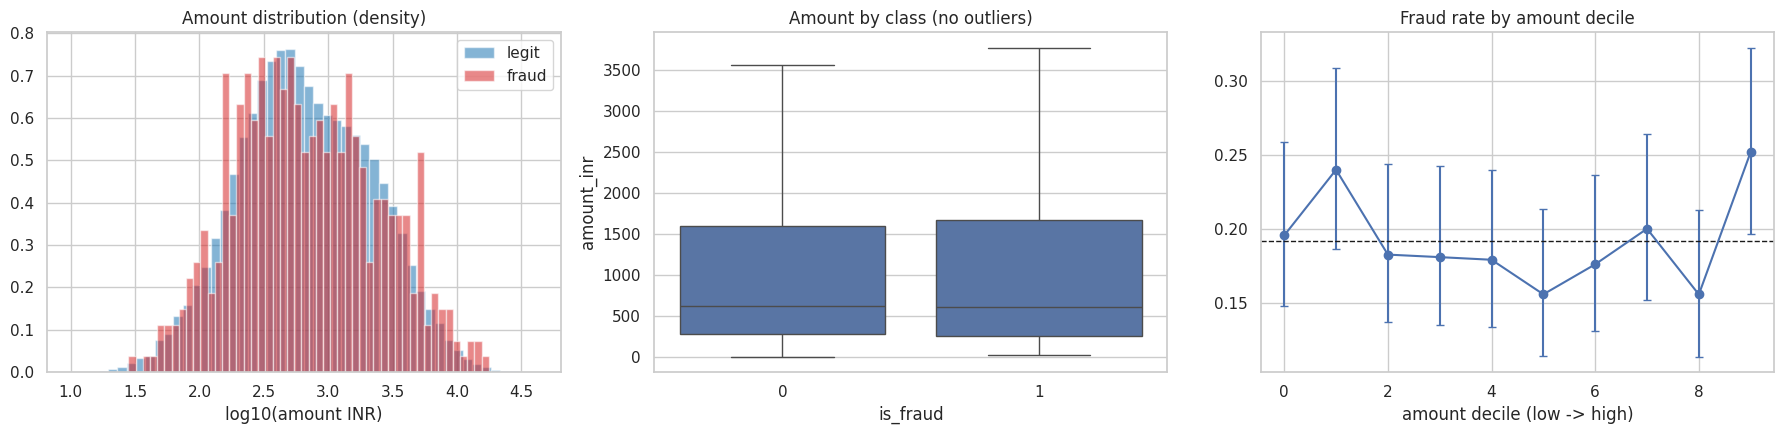

Mann-Whitney U on amount (fraud vs legit): p = 0.9911  | median fraud = 618, median legit = 629
Invalid amounts (<= 0): 0


In [11]:
# ---- 1.8 Transaction amount analysis ----
print(df.groupby(TARGET)["amount_inr"].describe().round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for lab, colr in [(0, "tab:blue"), (1, "tab:red")]:
    ax[0].hist(np.log10(df.loc[df[TARGET] == lab, "amount_inr"].clip(lower=1)), bins=50, alpha=.55, density=True,
               color=colr, label="fraud" if lab else "legit")
ax[0].set_xlabel("log10(amount INR)"); ax[0].set_title("Amount distribution (density)"); ax[0].legend()
sns.boxplot(data=df, x=TARGET, y="amount_inr", ax=ax[1], showfliers=False); ax[1].set_title("Amount by class (no outliers)")
df["_amt_decile"] = pd.qcut(df["amount_inr"], 10, duplicates="drop")
d = fraud_table(df, "_amt_decile", sort=False)
ax[2].errorbar(range(len(d)), d["fraud_rate_pct"], yerr=[d["fraud_rate_pct"] - d["ci_low"], d["ci_high"] - d["fraud_rate_pct"]], fmt="o-", capsize=3)
ax[2].axhline(overall_rate, ls="--", c="k", lw=1); ax[2].set_xlabel("amount decile (low -> high)"); ax[2].set_title("Fraud rate by amount decile")
plt.tight_layout(); plt.show()
df = df.drop(columns="_amt_decile")

fraud_amt = df.loc[df[TARGET] == 1, "amount_inr"]; legit_amt = df.loc[df[TARGET] == 0, "amount_inr"]
if len(fraud_amt) > 0:
    u = stats.mannwhitneyu(fraud_amt, legit_amt, alternative="two-sided")
    print(f"Mann-Whitney U on amount (fraud vs legit): p = {u.pvalue:.4g}  | median fraud = {fraud_amt.median():.0f}, median legit = {legit_amt.median():.0f}")
print("Invalid amounts (<= 0):", int((df["amount_inr"] <= 0).sum()))

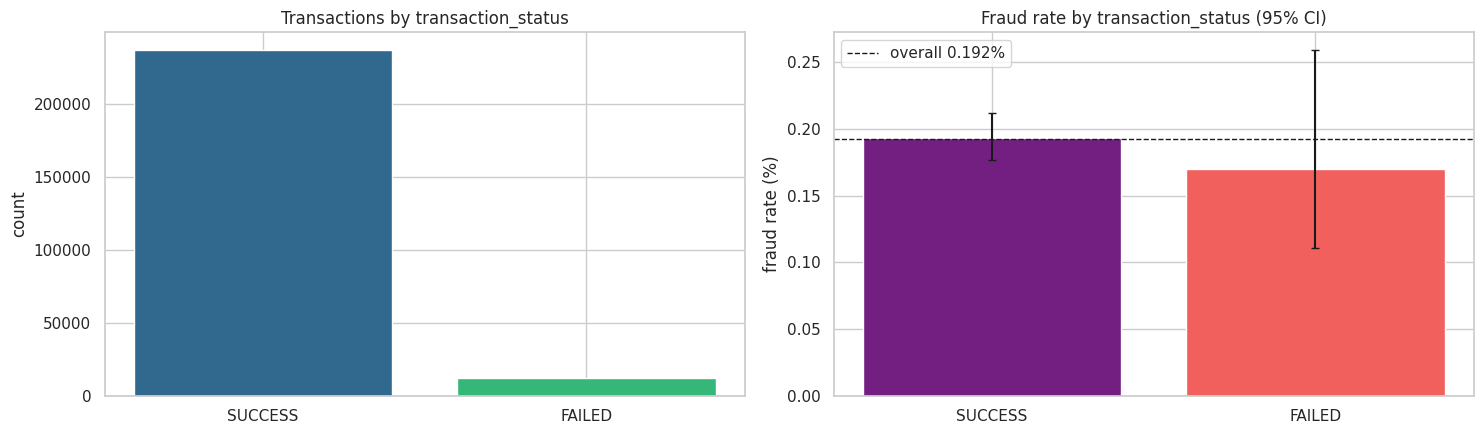

,transactions,frauds,fraud_rate_pct,ci_low,ci_high
transaction_status,,,,,
SUCCESS,237624,459,0.1932,0.1763,0.2116
FAILED,12376,21,0.1697,0.1110,0.2593


is_fraud,0,1,All
transaction_status,,,
FAILED,12355,21,12376
SUCCESS,237165,459,237624
All,249520,480,250000


NOTE: transaction_status is an *outcome* of the transaction. It is analysed here but deliberately excluded from model features to avoid target leakage (it may be set differently once a transaction is flagged).


In [12]:
# ---- 1.9 Transaction status analysis ----
g = plot_volume_and_fraud(df, "transaction_status")
display(g.round(4))
display(pd.crosstab(df["transaction_status"], df[TARGET], margins=True))
print("NOTE: transaction_status is an *outcome* of the transaction. It is analysed here but deliberately excluded "
      "from model features to avoid target leakage (it may be set differently once a transaction is flagged).")

In [13]:
# ---- 1.10 Which dimensions carry statistical signal? (chi-square / Cramer's V) ----
eda_cats = ["transaction_type", "merchant_category", "sender_age_group", "receiver_age_group", "sender_state", "sender_bank",
            "receiver_bank", "device_type", "network_type", "transaction_status", "hour", "day_name"]
rows = []
for c in [c for c in eda_cats if c in df.columns]:
    ct = pd.crosstab(df[c], df[TARGET])
    if ct.shape[0] < 2 or ct.shape[1] < 2: continue
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({"feature": c, "chi2": chi2, "dof": dof, "p_value": p,
                 "cramers_v": np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))})
sig = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
alpha_bonf = 0.05 / max(len(sig), 1)
sig["significant_bonferroni"] = sig["p_value"] < alpha_bonf
display(sig.round(5))
print(f"Bonferroni-corrected alpha = {alpha_bonf:.4f}  (we test {len(sig)} features at once, so plain p<0.05 would give false alarms).")
if not sig["significant_bonferroni"].any():
    print("\n>> EDA FINDING: no single categorical dimension is significantly associated with fraud after correction. "
          "Expect weak predictive signal; the modelling phases will test whether combinations help.")
else:
    print("\n>> EDA FINDING: dimensions with significant association:", list(sig.loc[sig.significant_bonferroni, "feature"]))

,feature,chi2,dof,p_value,cramers_v,significant_bonferroni
0,sender_age_group,11.09533,4,0.02551,0.00666,False
1,receiver_age_group,7.35230,4,0.11840,0.00542,False
2,sender_bank,9.20291,7,0.23841,0.00607,False
3,network_type,2.72884,3,0.43535,0.00330,False
4,transaction_type,2.32376,3,0.50799,0.00305,False
5,sender_state,7.76448,9,0.55804,0.00557,False
6,transaction_status,0.22696,1,0.63378,0.00095,False
7,day_name,3.64503,6,0.72458,0.00382,False
8,device_type,0.45652,2,0.79592,0.00135,False
9,hour,15.89504,23,0.85973,0.00797,False


Bonferroni-corrected alpha = 0.0042  (we test 12 features at once, so plain p<0.05 would give false alarms).

>> EDA FINDING: no single categorical dimension is significantly associated with fraud after correction. Expect weak predictive signal; the modelling phases will test whether combinations help.


---
# Phase 2 — Data Preprocessing (UPI)
Duplicate analysis → missing-value checks → timestamp/categorical transforms → **chronological** train/validation/test split → class-imbalance handling → scikit-learn pipelines (fit on train only, reused unchanged for validation, test and inference).

In [14]:
# ---- 2.1 Duplicate analysis ----
ID_COL = "transaction_id"
dup_ids = int(df[ID_COL].duplicated().sum())
content_cols = [c for c in df.columns if c not in (ID_COL,)]
dup_content = df.duplicated(subset=content_cols, keep="first")
print(f"Duplicate transaction IDs                        : {dup_ids}")
print(f"Rows identical in every field except the ID      : {int(dup_content.sum())}")
if dup_content.sum():
    print(f"   fraud rate among those rows: {df.loc[dup_content, TARGET].mean() * 100:.3f}%  (overall {overall_rate:.3f}%)")

# A repeated transaction ID is a true duplicate record -> drop.
# Rows that merely look identical but have different IDs can be genuine repeated payments -> keep, but report.
if dup_ids:
    df = df.drop_duplicates(subset=ID_COL, keep="first").reset_index(drop=True)
    print(f"Dropped {dup_ids} rows with repeated transaction IDs. New shape: {df.shape}")

# ---- 2.2 Missing-value checks ----
obj_cols = df.select_dtypes(include="object").columns
df[obj_cols] = df[obj_cols].replace(r"^\s*$", np.nan, regex=True)    # blank strings count as missing
miss = df.isna().sum()
print("\nMissing values per column:")
print(miss[miss > 0] if miss.sum() else "  none")
print("Non-positive amounts:", int((df["amount_inr"] <= 0).sum()))
print("Target values:", sorted(df[TARGET].unique()))
assert set(df[TARGET].unique()) <= {0, 1}, "Target must be binary"

Duplicate transaction IDs                        : 0
Rows identical in every field except the ID      : 0

Missing values per column:
  none
Non-positive amounts: 0
Target values: [np.int64(0), np.int64(1)]


In [15]:
# ---- 2.3 Chronological train / validation / test split (70 / 15 / 15) ----
assert df["timestamp"].is_monotonic_increasing, "df must be sorted by time before splitting"
n = len(df)
i_tr, i_va = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
df["split"] = "test"
df.loc[: i_tr - 1, "split"] = "train"
df.loc[i_tr: i_va - 1, "split"] = "val"

summary = df.groupby("split").agg(rows=(TARGET, "size"), frauds=(TARGET, "sum"),
                                  start=("timestamp", "min"), end=("timestamp", "max"))
summary["fraud_rate_pct"] = summary["frauds"] / summary["rows"] * 100
display(summary.loc[["train", "val", "test"]].round(4))
for s in ["train", "val", "test"]:
    assert summary.loc[s, "frauds"] > 0, f"No fraud in {s} split. Check the data."
print("Why chronological? A random split would let the model train on the future and be tested on the past, "
      "which inflates scores and does not match how a fraud system is actually deployed.")

,rows,frauds,start,end,fraud_rate_pct
split,,,,,
train,175000,325,2024-01-01 00:05:10,2024-09-12 17:03:58,0.1857
val,37500,88,2024-09-12 17:04:19,2024-11-06 07:06:12,0.2347
test,37500,67,2024-11-06 07:09:06,2024-12-30 23:55:40,0.1787


Why chronological? A random split would let the model train on the future and be tested on the past, which inflates scores and does not match how a fraud system is actually deployed.


In [16]:
# ---- 2.4 Class imbalance handling ----
y_tr_raw = df.loc[df.split == "train", TARGET]
n_neg, n_pos = int((y_tr_raw == 0).sum()), int((y_tr_raw == 1).sum())
print(f"Training class counts: legit={n_neg:,}  fraud={n_pos:,}  (ratio {n_neg / n_pos:,.0f}:1)")

# Primary strategy: cost-sensitive learning (class weights), applied inside each model, so no synthetic rows are created
# and validation/test remain untouched real data. A SMOTE variant is compared in Phase 4.
SPW = float(np.sqrt(n_neg / n_pos))     # damped weight for XGBoost: the full ratio over-fits a few hundred positives
print(f"LogReg/RandomForest: class_weight='balanced' | XGBoost scale_pos_weight = sqrt(ratio) = {SPW:.1f}")

# ---- 2.5 Preprocessing pipeline (fit on the training split only) ----
BASE_NUM = ["amount_inr", "hour", "dow", "is_weekend"]
BASE_CAT = ["transaction_type", "merchant_category", "sender_age_group", "receiver_age_group",
            "sender_state", "sender_bank", "receiver_bank", "device_type", "network_type"]
BASE_CAT = [c for c in BASE_CAT if c in df.columns]

def make_preprocessor(num_cols, cat_cols):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, list(num_cols)), ("cat", cat, list(cat_cols))])

print("Base numeric:", BASE_NUM)
print("Base categorical:", BASE_CAT)
print("Excluded on purpose: transaction_id (identifier), timestamp (decomposed), transaction_status (outcome / leakage risk).")

Training class counts: legit=174,675  fraud=325  (ratio 537:1)
LogReg/RandomForest: class_weight='balanced' | XGBoost scale_pos_weight = sqrt(ratio) = 23.2
Base numeric: ['amount_inr', 'hour', 'dow', 'is_weekend']
Base categorical: ['transaction_type', 'merchant_category', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type']
Excluded on purpose: transaction_id (identifier), timestamp (decomposed), transaction_status (outcome / leakage risk).


---
# Phase 3 — Feature Engineering (UPI)
Engineered features:

| Feature | Meaning |
|---|---|
| `is_night_time` | 10 PM – 6 AM |
| `is_cross_bank` | sender bank ≠ receiver bank |
| `is_high_value` | amount above the 95th percentile **of the training split** |
| `txn_velocity_1h` / `txn_velocity_24h` | transactions by the same sender profile in the last hour / 24 hours |
| `sender_cumulative_frequency` | how many transactions that sender profile has made so far |
| `log_secs_since_prev` | log time since that profile's previous transaction |
| `amount_to_group_mean_ratio` | amount ÷ that profile's average previous amount |
| `hour_sin`, `hour_cos` | cyclical encoding of the hour |

**Important caveat:** the dataset has no user/account ID, so a "sender profile" is approximated by `(sender_state, sender_bank, sender_age_group)`. These are *cohort-level* behavioural features, not true per-user velocity. All behavioural features look **backwards only**, so no future information leaks into a row.

**Watch-out:** `sender_cumulative_frequency` only ever grows over the timeline, so in validation/test it takes values never seen in training and can act as a proxy for "what time period is this". If the ablation keeps it, treat that with suspicion, and prefer `txn_velocity_*` (rolling windows, stable over time).

In [17]:
SENDER_KEYS = [c for c in ["sender_state", "sender_bank", "sender_age_group"] if c in df.columns]
HOUR_NS, DAY_NS = 3_600 * 10**9, 24 * 3_600 * 10**9

def add_engineered_features(data, high_value_threshold):
    """Adds causal (backward-looking) features. `data` must be sorted by timestamp."""
    out = data.copy()
    assert out["timestamp"].is_monotonic_increasing
    ts = out["timestamp"].values.astype("datetime64[ns]").astype("int64")
    amt = out["amount_inr"].values.astype(float)
    m = len(out)
    v1, v24, cnt = np.ones(m), np.ones(m), np.ones(m)
    gap, ratio = np.full(m, np.nan), np.ones(m)

    for _, idx in out.groupby(SENDER_KEYS, observed=True).indices.items():
        t, a, k = ts[idx], amt[idx], np.arange(len(idx))
        v1[idx] = k - np.searchsorted(t, t - HOUR_NS, side="left") + 1     # window (t-1h, t], includes current txn
        v24[idx] = k - np.searchsorted(t, t - DAY_NS, side="left") + 1
        cnt[idx] = k + 1
        if len(idx) > 1:
            gap[idx[1:]] = (t[1:] - t[:-1]) / 1e9
            prev_mean = np.where(k > 0, (np.cumsum(a) - a) / np.maximum(k, 1), np.nan)
            with np.errstate(divide="ignore", invalid="ignore"):
                r = np.where(prev_mean > 0, a / prev_mean, np.nan)
            ratio[idx] = np.where(k > 0, r, 1.0)

    out["is_night_time"] = ((out["hour"] >= 22) | (out["hour"] <= 6)).astype(int)
    out["is_cross_bank"] = (out["sender_bank"] != out["receiver_bank"]).astype(int)
    out["is_high_value"] = (out["amount_inr"] > high_value_threshold).astype(int)
    out["txn_velocity_1h"] = v1
    out["txn_velocity_24h"] = v24
    out["sender_cumulative_frequency"] = cnt
    out["log_secs_since_prev"] = np.log1p(gap)                    # NaN for a profile's first txn -> imputed (median) in pipeline
    out["amount_to_group_mean_ratio"] = np.nan_to_num(ratio, nan=1.0, posinf=1.0)
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    return out

ENG_FEATURES = ["is_night_time", "is_cross_bank", "is_high_value", "txn_velocity_1h", "txn_velocity_24h",
                "sender_cumulative_frequency", "log_secs_since_prev", "amount_to_group_mean_ratio", "hour_sin", "hour_cos"]

HV_THRESHOLD = df.loc[df.split == "train", "amount_inr"].quantile(0.95)     # learned from TRAIN only
print(f"High-value threshold (95th pct of training amounts): INR {HV_THRESHOLD:,.0f}")
df_feat = add_engineered_features(df, HV_THRESHOLD)

train_df = df_feat[df_feat.split == "train"]
val_df   = df_feat[df_feat.split == "val"]
test_df  = df_feat[df_feat.split == "test"]
y_train, y_val, y_test = train_df[TARGET].values, val_df[TARGET].values, test_df[TARGET].values

print("\nCorrelation of each engineered feature with fraud (training split only):")
corr = train_df[ENG_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
display(corr.to_frame("pearson_r").round(5))

High-value threshold (95th pct of training amounts): INR 4,678

Correlation of each engineered feature with fraud (training split only):


,pearson_r
sender_cumulative_frequency,-0.00560
is_high_value,0.00533
amount_to_group_mean_ratio,0.00422
txn_velocity_1h,-0.00260
is_cross_bank,0.00197
txn_velocity_24h,-0.00195
log_secs_since_prev,0.00118
is_night_time,-0.00101
hour_cos,-0.00008
hour_sin,0.00007


In [18]:
# ---- Validate that each feature actually improves performance (validation PR-AUC) ----
# Method: a fixed, fast XGBoost on BASE features gives the reference score. We repeat it with 3 seeds to measure *noise*.
# A feature is kept only if adding it raises PR-AUC by more than 2x that noise (and by > 0).
def fit_score(num_cols, cat_cols, seed=RANDOM_STATE):
    pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols)),
                     ("clf", XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, subsample=0.8,
                                           colsample_bytree=0.8, scale_pos_weight=SPW, tree_method="hist",
                                           n_jobs=-1, random_state=seed, eval_metric="aucpr"))])
    pipe.fit(train_df[num_cols + cat_cols], y_train)
    p = pipe.predict_proba(val_df[num_cols + cat_cols])[:, 1]
    return average_precision_score(y_val, p), roc_auc_score(y_val, p)

base_runs = np.array([fit_score(BASE_NUM, BASE_CAT, seed) for seed in (1, 2, 3)])
base_pr, base_roc = base_runs[:, 0].mean(), base_runs[:, 1].mean()
noise = max(base_runs[:, 0].std(ddof=1), 1e-4)
print(f"BASE features: val PR-AUC = {base_pr:.5f} (+/- {noise:.5f} seed noise) | ROC-AUC = {base_roc:.4f} | fraud prevalence (val) = {y_val.mean():.5f}\n")

rows = []
for f in ENG_FEATURES:
    pr, roc = fit_score(BASE_NUM + [f], BASE_CAT)
    rows.append({"feature": f, "val_pr_auc": pr, "delta_pr_auc": pr - base_pr, "val_roc_auc": roc,
                 "keep": (pr - base_pr) > 2 * noise})
ablation = pd.DataFrame(rows).sort_values("delta_pr_auc", ascending=False).reset_index(drop=True)

all_pr, all_roc = fit_score(BASE_NUM + ENG_FEATURES, BASE_CAT)
display(ablation.round(5))
print(f"ALL engineered features together: val PR-AUC = {all_pr:.5f} (delta {all_pr - base_pr:+.5f}) | ROC-AUC = {all_roc:.4f}")

SELECTED_FEATURES = list(ablation.loc[ablation.keep, "feature"])
FINAL_NUM = BASE_NUM + SELECTED_FEATURES
FINAL_CAT = BASE_CAT
print("\nSelected engineered features:", SELECTED_FEATURES if SELECTED_FEATURES else "NONE (no feature beat the noise threshold)")
if not SELECTED_FEATURES:
    print("-> Final models use the base feature set. This is a legitimate result, not a bug.")

BASE features: val PR-AUC = 0.00271 (+/- 0.00024 seed noise) | ROC-AUC = 0.5004 | fraud prevalence (val) = 0.00235



,feature,val_pr_auc,delta_pr_auc,val_roc_auc,keep
0,amount_to_group_mean_ratio,0.01492,0.01221,0.50628,True
1,hour_sin,0.00328,0.00057,0.48327,True
2,txn_velocity_24h,0.00314,0.00042,0.49431,False
3,txn_velocity_1h,0.00266,-0.00006,0.48307,False
4,log_secs_since_prev,0.00261,-0.00011,0.51499,False
5,sender_cumulative_frequency,0.00252,-0.00019,0.49762,False
6,is_high_value,0.00250,-0.00021,0.48922,False
7,is_cross_bank,0.00249,-0.00022,0.49051,False
8,hour_cos,0.00243,-0.00028,0.47111,False
9,is_night_time,0.00240,-0.00032,0.48167,False


ALL engineered features together: val PR-AUC = 0.00253 (delta -0.00018) | ROC-AUC = 0.5045

Selected engineered features: ['amount_to_group_mean_ratio', 'hour_sin']


---
# Phase 4 — Model Development (UPI fraud model)
Logistic Regression, Random Forest and XGBoost, each wrapped in a single `Pipeline(preprocessor → model)` so training and inference use identical preprocessing. The **best model is selected on validation PR-AUC only**. The test set is not touched until Phase 5.

In [19]:
def build_models():
    prep = lambda: make_preprocessor(FINAL_NUM, FINAL_CAT)
    return {
        "Logistic Regression": Pipeline([("prep", prep()),
            ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([("prep", prep()),
            ("clf", RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=20,
                                           class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))]),
        "XGBoost": Pipeline([("prep", prep()),
            ("clf", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                  min_child_weight=5, scale_pos_weight=SPW, tree_method="hist", n_jobs=-1,
                                  random_state=RANDOM_STATE, eval_metric="aucpr"))]),
    }

FEATURES = FINAL_NUM + FINAL_CAT
models = build_models()
val_scores = {}
for name, pipe in models.items():
    pipe.fit(train_df[FEATURES], y_train)
    p = pipe.predict_proba(val_df[FEATURES])[:, 1]
    val_scores[name] = {"val_pr_auc": average_precision_score(y_val, p), "val_roc_auc": roc_auc_score(y_val, p)}
    print(f"{name:<20} val PR-AUC = {val_scores[name]['val_pr_auc']:.5f} | val ROC-AUC = {val_scores[name]['val_roc_auc']:.4f}")

BEST_MODEL = max(val_scores, key=lambda k: val_scores[k]["val_pr_auc"])
print(f"\nBest model on validation PR-AUC: {BEST_MODEL}   (random-guess PR-AUC = prevalence = {y_val.mean():.5f})")

Logistic Regression  val PR-AUC = 0.00306 | val ROC-AUC = 0.5167
Random Forest        val PR-AUC = 0.00253 | val ROC-AUC = 0.5099
XGBoost              val PR-AUC = 0.00296 | val ROC-AUC = 0.5276

Best model on validation PR-AUC: Logistic Regression   (random-guess PR-AUC = prevalence = 0.00235)


In [20]:
# ---- Optional comparison: class weights vs SMOTE (SMOTE applied inside the pipeline, training data only) ----
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    smote_lr = ImbPipeline([("prep", make_preprocessor(FINAL_NUM, FINAL_CAT)),
                            ("smote", SMOTE(sampling_strategy=0.05, random_state=RANDOM_STATE)),
                            ("clf", LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOM_STATE))])
    smote_lr.fit(train_df[FEATURES], y_train)
    ps = smote_lr.predict_proba(val_df[FEATURES])[:, 1]
    print(f"Logistic Regression + SMOTE (5% minority): val PR-AUC = {average_precision_score(y_val, ps):.5f} | ROC-AUC = {roc_auc_score(y_val, ps):.4f}")
    print(f"Logistic Regression + class weights      : val PR-AUC = {val_scores['Logistic Regression']['val_pr_auc']:.5f} | ROC-AUC = {val_scores['Logistic Regression']['val_roc_auc']:.4f}")
    print("-> Class weights are kept as the primary strategy (simpler, no synthetic rows) unless SMOTE is clearly better.")
except Exception as e:
    print("SMOTE comparison skipped:", e)

Logistic Regression + SMOTE (5% minority): val PR-AUC = 0.00290 | ROC-AUC = 0.5356
Logistic Regression + class weights      : val PR-AUC = 0.00306 | ROC-AUC = 0.5167
-> Class weights are kept as the primary strategy (simpler, no synthetic rows) unless SMOTE is clearly better.


---
# Phase 5 — Model Evaluation
Each model is evaluated independently on the **held-out test set** using: Precision, Recall, F1, PR-AUC, ROC-AUC and the confusion matrix. We report two operating points:

- **Default threshold (0.5)** — what a naive `predict()` would give.
- **Tuned threshold** — chosen on the *validation* set to maximise F1, then applied unchanged to test.

We then analyse the effect of the threshold, and attach bootstrap confidence intervals so we can tell real signal from luck.

> **Reminder:** this is one payment system. Raw accuracy/AUC must **not** be compared with a model from another dataset as evidence that one payment system is safer: the features and data-generating processes differ.

In [21]:
def best_f1_threshold(y, p):
    if y.sum() == 0: return 0.5
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return float(thr[int(np.argmax(f1))])

def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": float(thr), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp), "flagged": int(pred.sum())}

results = {}
for name, pipe in models.items():
    pv, pt = pipe.predict_proba(val_df[FEATURES])[:, 1], pipe.predict_proba(test_df[FEATURES])[:, 1]
    thr = best_f1_threshold(y_val, pv)
    results[name] = {"p_val": pv, "p_test": pt, "thr": thr,
                     "test_default": metrics_at(y_test, pt, 0.5), "test_tuned": metrics_at(y_test, pt, thr),
                     "val_tuned": metrics_at(y_val, pv, thr)}

prev_test = y_test.mean()
cols = ["precision", "recall", "f1", "pr_auc", "roc_auc", "tp", "fp", "fn", "tn", "flagged"]
tab = pd.concat({n: pd.DataFrame({"threshold 0.5": r["test_default"], "tuned threshold": r["test_tuned"]}).T[["threshold"] + cols]
                 for n, r in results.items()})
print(f"TEST SET: {len(y_test):,} transactions, {int(y_test.sum())} frauds (prevalence {prev_test:.5f}). A random model has PR-AUC ~ {prev_test:.5f} and ROC-AUC ~ 0.5.\n")
display(tab.round(4))

TEST SET: 37,500 transactions, 67 frauds (prevalence 0.00179). A random model has PR-AUC ~ 0.00179 and ROC-AUC ~ 0.5.



threshold  precision  recall      f1  pr_auc  roc_auc    tp       fp    fn       tn  flagged
Logistic Regression threshold 0.5       0.5000     0.0021  0.5224  0.0043  0.0024   0.5540  35.0  16245.0  32.0  21188.0  16280.0
                    tuned threshold     0.7061     0.0028  0.0149  0.0048  0.0024   0.5540   1.0    350.0  66.0  37083.0    351.0
Random Forest       threshold 0.5       0.5000     0.0000  0.0000  0.0000  0.0019   0.5150   0.0      0.0  67.0  37433.0      0.0
                    tuned threshold     0.3891     0.0000  0.0000  0.0000  0.0019   0.5150   0.0    140.0  67.0  37293.0    140.0
XGBoost             threshold 0.5       0.5000     0.0000  0.0000  0.0000  0.0021   0.5405   0.0      0.0  67.0  37433.0      0.0
                    tuned threshold     0.0997     0.0000  0.0000  0.0000  0.0021   0.5405   0.0    707.0  67.0  36726.0    707.0

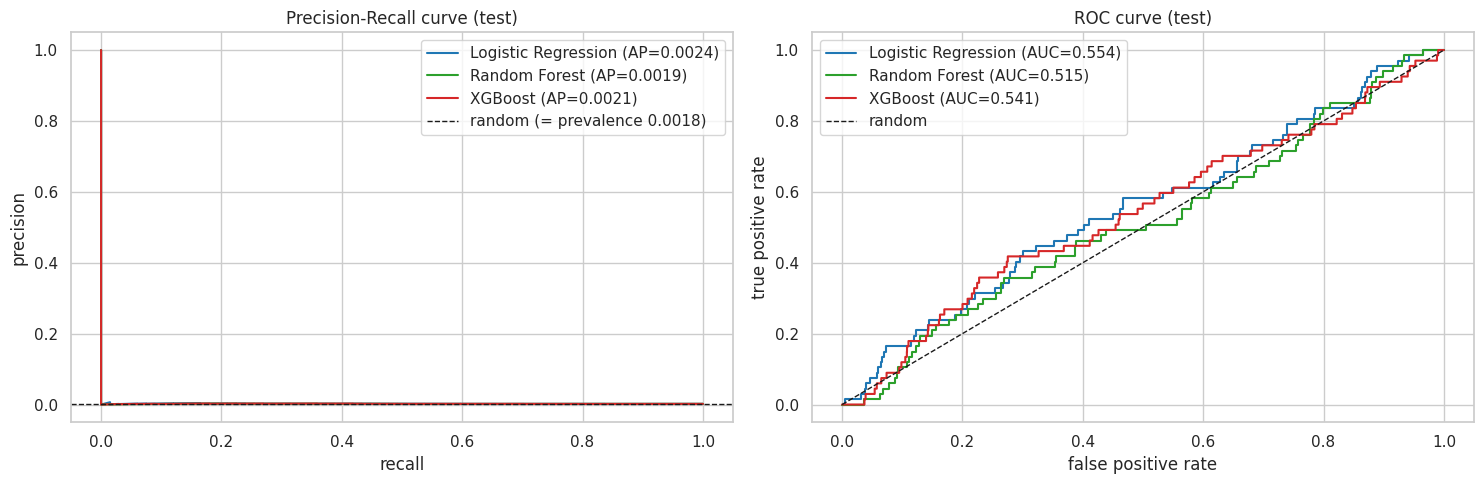

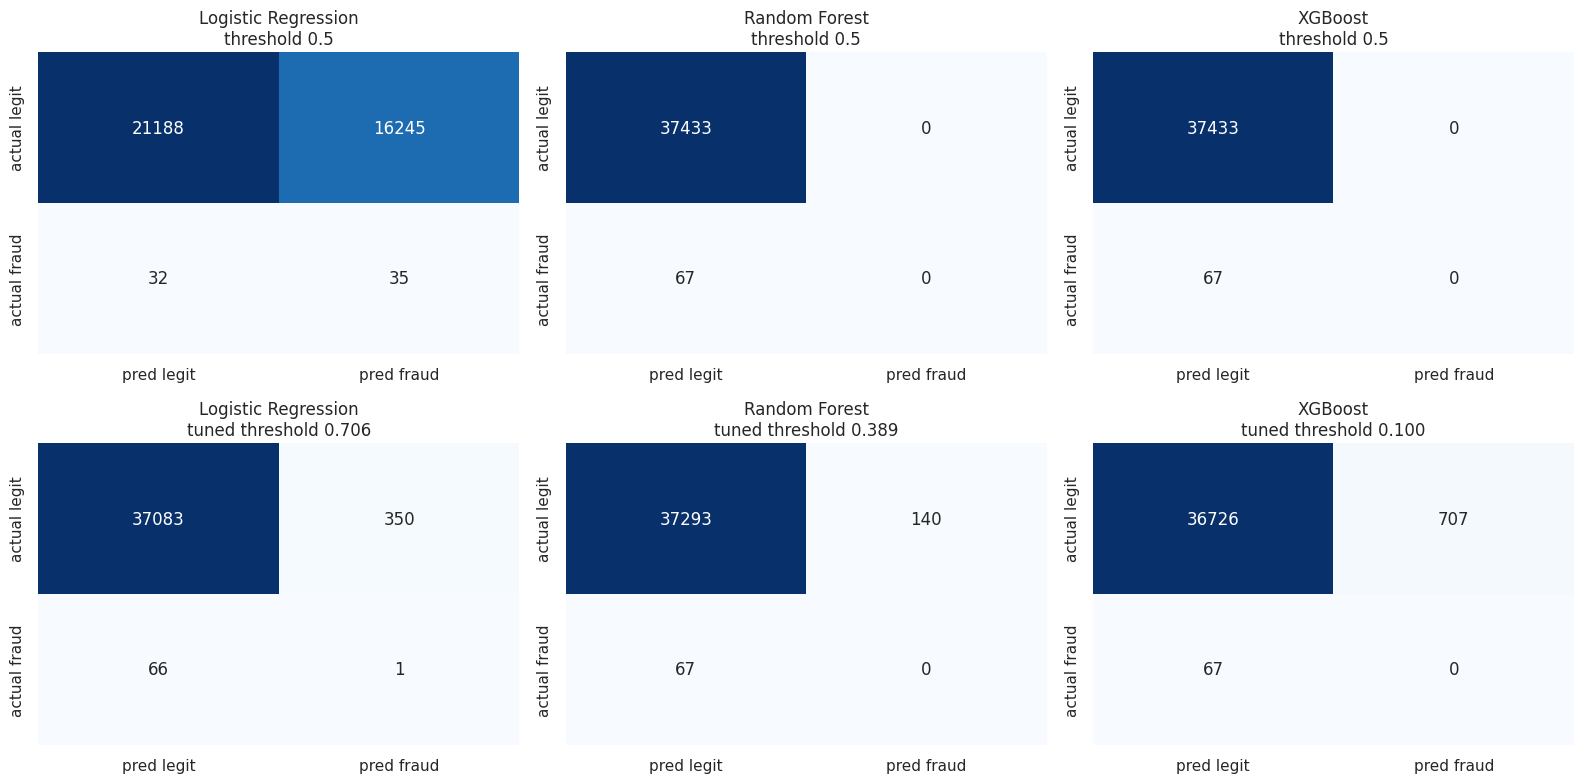

In [22]:
# ---- Curves and confusion matrices ----
colors = {"Logistic Regression": "tab:blue", "Random Forest": "tab:green", "XGBoost": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name, r in results.items():
    pr, rc, _ = precision_recall_curve(y_test, r["p_test"])
    ax[0].plot(rc, pr, color=colors[name], label=f"{name} (AP={r['test_tuned']['pr_auc']:.4f})")
    fpr, tpr, _ = roc_curve(y_test, r["p_test"])
    ax[1].plot(fpr, tpr, color=colors[name], label=f"{name} (AUC={r['test_tuned']['roc_auc']:.3f})")
ax[0].axhline(prev_test, ls="--", c="k", lw=1, label=f"random (= prevalence {prev_test:.4f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-Recall curve (test)"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="random"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
ax[1].set_title("ROC curve (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, (name, r) in enumerate(results.items()):
    for i, key in enumerate(["test_default", "test_tuned"]):
        m = r[key]
        cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j],
                    xticklabels=["pred legit", "pred fraud"], yticklabels=["actual legit", "actual fraud"])
        sub = "threshold 0.5" if i == 0 else "tuned threshold %.3f" % m["threshold"]
        axes[i, j].set_title(name + "\n" + sub)
plt.tight_layout(); plt.show()

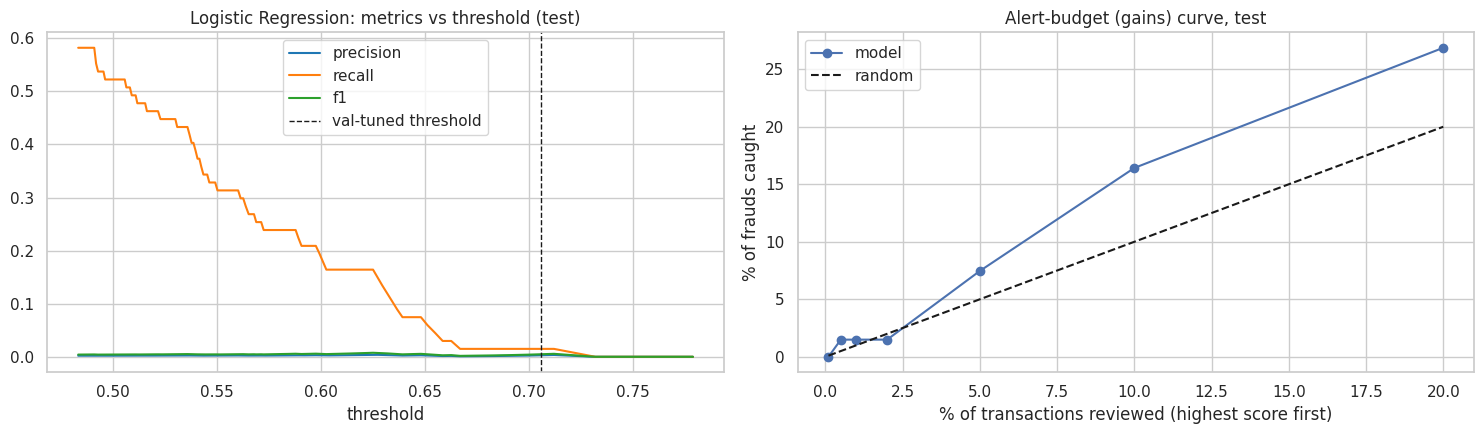

,review_top_%,flagged,frauds_caught,recall_%,precision_%,lift_vs_random
0,0.1,37,0,0.000,0.000,0.000
1,0.5,187,1,1.493,0.535,2.993
2,1.0,375,1,1.493,0.267,1.493
3,2.0,750,1,1.493,0.133,0.746
4,5.0,1875,5,7.463,0.267,1.493
5,10.0,3750,11,16.418,0.293,1.642
6,20.0,7500,18,26.866,0.240,1.343


In [23]:
# ---- Impact of the classification threshold (best model) ----
bp_val, bp_test = results[BEST_MODEL]["p_val"], results[BEST_MODEL]["p_test"]
grid = np.unique(np.quantile(bp_val, np.linspace(0.50, 0.9995, 150)))
sweep = pd.DataFrame([{"threshold": t, **{f"val_{k}": metrics_at(y_val, bp_val, t)[k] for k in ("precision", "recall", "f1")},
                       **{f"test_{k}": metrics_at(y_test, bp_test, t)[k] for k in ("precision", "recall", "f1", "flagged")}} for t in grid])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for k, c in [("precision", "tab:blue"), ("recall", "tab:orange"), ("f1", "tab:green")]:
    ax[0].plot(sweep["threshold"], sweep[f"test_{k}"], label=k, color=c)
ax[0].axvline(results[BEST_MODEL]["thr"], ls="--", c="k", lw=1, label="val-tuned threshold")
ax[0].set_xlabel("threshold"); ax[0].set_title(f"{BEST_MODEL}: metrics vs threshold (test)"); ax[0].legend()

# Alert-budget view: "if analysts can review the top k% highest-scoring transactions, how much fraud do we catch?"
order = np.argsort(-bp_test); rows = []
for k in [0.1, 0.5, 1, 2, 5, 10, 20]:
    top = order[: max(int(len(order) * k / 100), 1)]
    caught = y_test[top].sum()
    rows.append({"review_top_%": k, "flagged": len(top), "frauds_caught": int(caught),
                 "recall_%": caught / max(y_test.sum(), 1) * 100, "precision_%": caught / len(top) * 100,
                 "lift_vs_random": (caught / len(top)) / prev_test if prev_test > 0 else np.nan})
budget = pd.DataFrame(rows)
ax[1].plot(budget["review_top_%"], budget["recall_%"], "o-", label="model"); ax[1].plot(budget["review_top_%"], budget["review_top_%"], "k--", label="random")
ax[1].set_xlabel("% of transactions reviewed (highest score first)"); ax[1].set_ylabel("% of frauds caught"); ax[1].set_title("Alert-budget (gains) curve, test"); ax[1].legend()
plt.tight_layout(); plt.show()
display(budget.round(3))

In [24]:
# ---- Is the signal real? Stratified bootstrap CIs on the test set ----
def strat_bootstrap(y, p, fn, n_boot=300, seed=0):
    rng = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]
        vals.append(fn(y[idx], p[idx]))
    return [float(x) for x in np.percentile(vals, [2.5, 97.5])]

ci_rows = []
for name, r in results.items():
    r["ci_pr"] = strat_bootstrap(y_test, r["p_test"], average_precision_score)
    r["ci_roc"] = strat_bootstrap(y_test, r["p_test"], roc_auc_score)
    real = (r["ci_roc"][0] > 0.5) and (r["ci_pr"][0] > prev_test)
    ci_rows.append({"model": name, "test_pr_auc": r["test_tuned"]["pr_auc"], "pr_auc_95ci": f"[{r['ci_pr'][0]:.4f}, {r['ci_pr'][1]:.4f}]",
                    "test_roc_auc": r["test_tuned"]["roc_auc"], "roc_auc_95ci": f"[{r['ci_roc'][0]:.3f}, {r['ci_roc'][1]:.3f}]",
                    "beats_random": real})
ci_table = pd.DataFrame(ci_rows); display(ci_table.round(4))

print(f"Baselines: PR-AUC of a random model = prevalence = {prev_test:.5f}; ROC-AUC of a random model = 0.5")
best_ok = ci_table.set_index("model").loc[BEST_MODEL, "beats_random"]
print("\n" + "=" * 78)
if best_ok:
    print(f"VERDICT: {BEST_MODEL} shows statistically detectable signal above random on the test set.\n"
          f"         Still judge usefulness by the alert-budget table (precision at a reviewable volume), not by AUC alone.")
else:
    print(f"VERDICT: {BEST_MODEL}'s test PR-AUC / ROC-AUC CIs include random-level performance.\n"
          "         The features in this dataset do not give a reliable fraud signal. The most likely causes are that the\n"
          "         labels are weakly related to the features (common in synthetic data) or that the predictive information\n"
          "         is not in these columns. Report this honestly; do not tune thresholds until the numbers look good.")
print("=" * 78)
print(f"Caution: the test set has only {int(y_test.sum())} frauds, so all test metrics are noisy; read the confidence intervals.")

,model,test_pr_auc,pr_auc_95ci,test_roc_auc,roc_auc_95ci,beats_random
0,Logistic Regression,0.0024,"[0.0019, 0.0037]",0.5540,"[0.491, 0.630]",False
1,Random Forest,0.0019,"[0.0016, 0.0025]",0.5150,"[0.446, 0.578]",False
2,XGBoost,0.0021,"[0.0017, 0.0027]",0.5405,"[0.466, 0.607]",False


Baselines: PR-AUC of a random model = prevalence = 0.00179; ROC-AUC of a random model = 0.5

VERDICT: Logistic Regression's test PR-AUC / ROC-AUC CIs include random-level performance.
         The features in this dataset do not give a reliable fraud signal. The most likely causes are that the
         labels are weakly related to the features (common in synthetic data) or that the predictive information
         is not in these columns. Report this honestly; do not tune thresholds until the numbers look good.
Caution: the test set has only 67 frauds, so all test metrics are noisy; read the confidence intervals.


---
# Phase 6 — Fraud Monitoring Dashboard (Streamlit + Plotly)
The notebook saves everything the dashboard needs into `artifacts/` and writes a standalone `app.py`. The dashboard has four pages:

| Page | Contents |
|---|---|
| **Overview** | Total transactions, fraud count, fraud %, legitimate transactions, fraud trend |
| **Transaction Analytics** | Amount distributions, volume trends, category / type / time analysis |
| **Fraud Analysis** | Fraud rate by any dimension, fraud by hour and amount, highest-risk transactions |
| **Model Performance** | Precision, recall, F1, PR-AUC, ROC-AUC, confusion matrix, model comparison, live threshold slider |

In [25]:
# ---- 6.1 Save artifacts for the dashboard ----
def to_py(o):
    if isinstance(o, dict):  return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)):    return bool(o)
    return o

def thin(a, b, n=250):
    a, b = np.asarray(a), np.asarray(b)
    if len(a) <= n: return a.tolist(), b.tolist()
    idx = np.unique(np.linspace(0, len(a) - 1, n).astype(int))
    return a[idx].tolist(), b[idx].tolist()

best_pipe = models[BEST_MODEL]
joblib.dump({"pipeline": best_pipe, "features_num": FINAL_NUM, "features_cat": FINAL_CAT, "threshold": results[BEST_MODEL]["thr"],
             "high_value_threshold": float(HV_THRESHOLD), "model_name": BEST_MODEL}, f"{ARTIFACT_DIR}/best_model.joblib")

# Score every row with the best model; the dashboard marks which rows are in-sample (train) vs held-out (val/test)
df_feat["fraud_score"] = best_pipe.predict_proba(df_feat[FEATURES])[:, 1]
keep_cols = ["transaction_id", "timestamp", "transaction_type", "merchant_category", "amount_inr", "transaction_status",
             "sender_age_group", "receiver_age_group", "sender_state", "sender_bank", "receiver_bank", "device_type",
             "network_type", TARGET, "hour", "dow", "day_name", "is_weekend", "split", "fraud_score"]
dash = df_feat[[c for c in keep_cols if c in df_feat.columns]].copy()
dash.to_csv(f"{ARTIFACT_DIR}/dashboard_data.csv.gz", index=False, compression="gzip")

curves = {}
for name, r in results.items():
    pr, rc, _ = precision_recall_curve(y_test, r["p_test"]); fpr, tpr, _ = roc_curve(y_test, r["p_test"])
    rc_t, pr_t = thin(rc, pr); fpr_t, tpr_t = thin(fpr, tpr)
    curves[name] = {"pr": {"recall": rc_t, "precision": pr_t}, "roc": {"fpr": fpr_t, "tpr": tpr_t}}

metrics = {
    "best_model": BEST_MODEL,
    "prevalence_test": float(prev_test), "n_test": int(len(y_test)), "frauds_test": int(y_test.sum()),
    "feature_sets": {"numeric": FINAL_NUM, "categorical": FINAL_CAT, "selected_engineered": SELECTED_FEATURES},
    "ablation": ablation.to_dict(orient="records"),
    "models": {n: {"threshold": r["thr"], "val_tuned": r["val_tuned"], "test_default": r["test_default"],
                   "test_tuned": r["test_tuned"], "ci_pr_auc": r["ci_pr"], "ci_roc_auc": r["ci_roc"], "curves": curves[n]}
               for n, r in results.items()},
}
with open(f"{ARTIFACT_DIR}/metrics.json", "w") as f:
    json.dump(to_py(metrics), f)
print("Saved:", sorted(os.listdir(ARTIFACT_DIR)))
print(f"dashboard_data rows: {len(dash):,}  | size: {os.path.getsize(f'{ARTIFACT_DIR}/dashboard_data.csv.gz') / 1e6:.1f} MB")

Saved: ['best_model.joblib', 'dashboard_data.csv.gz', 'metrics.json']
dashboard_data rows: 250,000  | size: 7.6 MB


In [26]:
# ---- Inference helper: how the saved model scores a brand-new transaction (identical preprocessing) ----
bundle = joblib.load(f"{ARTIFACT_DIR}/best_model.joblib")
sample = test_df[FEATURES].iloc[[0]]
print("Model:", bundle["model_name"], "| decision threshold:", round(bundle["threshold"], 4))
print("Fraud probability for a sample test transaction:", float(bundle["pipeline"].predict_proba(sample)[0, 1]))

Model: Logistic Regression | decision threshold: 0.7061
Fraud probability for a sample test transaction: 0.4906722444319117


In [27]:
%%writefile app.py
import json, os
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

ART = os.environ.get("UPI_ARTIFACT_DIR", "artifacts")
st.set_page_config(page_title="UPI Fraud Monitor", page_icon=":mag:", layout="wide")


@st.cache_data
def load_data():
    d = pd.read_csv(f"{ART}/dashboard_data.csv.gz", parse_dates=["timestamp"])
    d["date"] = d["timestamp"].dt.floor("D")
    with open(f"{ART}/metrics.json") as f:
        m = json.load(f)
    return d, m


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.maximum(np.asarray(n, float), 1)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (centre - half) * 100, (centre + half) * 100


def rate_table(d, col):
    g = d.groupby(col, observed=True)["is_fraud"].agg(transactions="size", frauds="sum").reset_index()
    g["fraud_rate_pct"] = g["frauds"] / g["transactions"] * 100
    g["ci_low"], g["ci_high"] = wilson(g["frauds"], g["transactions"])
    return g


data, M = load_data()

# ------------------------------- sidebar --------------------------------
st.sidebar.title("UPI Fraud Monitor")
page = st.sidebar.radio("Page", ["Overview", "Transaction Analytics", "Fraud Analysis", "Model Performance"])
st.sidebar.markdown("---")
st.sidebar.subheader("Filters")
dmin, dmax = data["date"].min().date(), data["date"].max().date()
rng = st.sidebar.date_input("Date range", (dmin, dmax), min_value=dmin, max_value=dmax)
types = sorted(data["transaction_type"].dropna().unique())
sel_types = st.sidebar.multiselect("Transaction type", types, default=types)

f = data[data["transaction_type"].isin(sel_types)]
if isinstance(rng, (list, tuple)) and len(rng) == 2:
    f = f[(f["date"].dt.date >= rng[0]) & (f["date"].dt.date <= rng[1])]
if f.empty:
    st.warning("No transactions match the current filters.")
    st.stop()

overall_rate = f["is_fraud"].mean() * 100

# ------------------------------- Overview --------------------------------
if page == "Overview":
    st.title("Overview")
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Total transactions", f"{len(f):,}")
    c2.metric("Fraud transactions", f"{int(f['is_fraud'].sum()):,}")
    c3.metric("Fraud percentage", f"{overall_rate:.3f}%")
    c4.metric("Legitimate transactions", f"{int((f['is_fraud'] == 0).sum()):,}")

    left, right = st.columns([1, 2])
    pie = px.pie(names=["Legitimate", "Fraud"], values=[int((f["is_fraud"] == 0).sum()), int(f["is_fraud"].sum())],
                 hole=0.55, color_discrete_sequence=["#4C78A8", "#E45756"], title="Class balance")
    left.plotly_chart(pie)
    wk = f.set_index("timestamp").resample("W")["is_fraud"].agg(["sum", "size"]).reset_index()
    wk["fraud_rate_pct"] = wk["sum"] / wk["size"].clip(lower=1) * 100
    fig = go.Figure()
    fig.add_bar(x=wk["timestamp"], y=wk["sum"], name="Fraud count", marker_color="#E45756")
    fig.add_scatter(x=wk["timestamp"], y=wk["fraud_rate_pct"], name="Fraud rate (%)", yaxis="y2", line=dict(color="#333"))
    fig.update_layout(title="Weekly fraud count and rate", yaxis2=dict(overlaying="y", side="right", title="rate (%)"),
                      yaxis=dict(title="frauds"), legend=dict(orientation="h"))
    right.plotly_chart(fig)
    st.caption("Fraud is rare, so weekly counts are small and noisy. Read trends with caution.")

# ------------------------- Transaction Analytics -------------------------
elif page == "Transaction Analytics":
    st.title("Transaction Analytics")
    a, b = st.columns(2)
    fig = px.histogram(f, x="amount_inr", color=f["is_fraud"].map({0: "Legitimate", 1: "Fraud"}), nbins=60, log_x=True,
                       histnorm="probability density", barmode="overlay", opacity=0.6,
                       color_discrete_map={"Legitimate": "#4C78A8", "Fraud": "#E45756"},
                       title="Amount distribution (log scale, density)", labels={"color": "class", "amount_inr": "amount (INR)"})
    a.plotly_chart(fig)
    daily = f.groupby("date").size().reset_index(name="transactions")
    daily["7-day mean"] = daily["transactions"].rolling(7, min_periods=1).mean()
    fig = px.line(daily, x="date", y=["transactions", "7-day mean"], title="Daily transaction volume")
    b.plotly_chart(fig)

    order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    heat = f.pivot_table(index="day_name", columns="hour", values="is_fraud", aggfunc="size").reindex(order)
    st.plotly_chart(px.imshow(heat, aspect="auto", color_continuous_scale="Blues",
                              title="Transaction volume: weekday x hour", labels=dict(color="transactions")))

    dim = st.selectbox("Break down volume and average amount by", [c for c in ["transaction_type", "merchant_category", "sender_bank",
                       "receiver_bank", "sender_state", "device_type", "network_type", "transaction_status"] if c in f.columns])
    g = f.groupby(dim).agg(transactions=("is_fraud", "size"), avg_amount=("amount_inr", "mean"),
                           median_amount=("amount_inr", "median")).reset_index().sort_values("transactions", ascending=False)
    c, d = st.columns(2)
    c.plotly_chart(px.bar(g, x=dim, y="transactions", title=f"Transactions by {dim}"))
    d.plotly_chart(px.bar(g, x=dim, y="avg_amount", title=f"Average amount (INR) by {dim}"))

# ----------------------------- Fraud Analysis ----------------------------
elif page == "Fraud Analysis":
    st.title("Fraud Analysis")
    st.caption("Bars show the fraud rate with a 95% Wilson confidence interval. The dashed line is the overall rate in the current filter. "
               "Intervals that overlap the line mean the difference could be chance.")
    dims = [c for c in ["transaction_type", "merchant_category", "sender_bank", "receiver_bank", "sender_state", "device_type",
                        "network_type", "transaction_status", "sender_age_group", "receiver_age_group", "day_name", "hour"] if c in f.columns]
    dim = st.selectbox("Fraud rate by", dims)
    g = rate_table(f, dim).sort_values("fraud_rate_pct", ascending=False)
    fig = go.Figure(go.Bar(x=g[dim].astype(str), y=g["fraud_rate_pct"],
                           error_y=dict(type="data", symmetric=False, array=g["ci_high"] - g["fraud_rate_pct"],
                                        arrayminus=g["fraud_rate_pct"] - g["ci_low"]),
                           customdata=np.c_[g["transactions"], g["frauds"]],
                           hovertemplate="%{x}<br>rate %{y:.3f}%<br>transactions %{customdata[0]:,}<br>frauds %{customdata[1]}<extra></extra>",
                           marker_color="#E45756"))
    fig.add_hline(y=overall_rate, line_dash="dash", annotation_text=f"overall {overall_rate:.3f}%")
    fig.update_layout(yaxis_title="fraud rate (%)", title=f"Fraud rate by {dim}")
    st.plotly_chart(fig)

    a, b = st.columns(2)
    f2 = f.copy()
    f2["amount_band"] = pd.qcut(f2["amount_inr"], 10, duplicates="drop").astype(str)
    band_order = f2.groupby("amount_band")["amount_inr"].min().sort_values().index.tolist()
    g2 = rate_table(f2, "amount_band").set_index("amount_band").loc[band_order].reset_index()
    a.plotly_chart(px.line(g2, x="amount_band", y="fraud_rate_pct", markers=True, title="Fraud rate by amount decile"))
    box = px.box(f, x=f["is_fraud"].map({0: "Legitimate", 1: "Fraud"}), y="amount_inr", log_y=True, points=False,
                 title="Amount by class (log scale)", labels={"x": "class", "amount_inr": "amount (INR)"})
    b.plotly_chart(box)

    st.subheader("Highest-risk transactions (model score)")
    scope = st.radio("Rows to rank", ["Held-out only (val + test)", "All rows (train rows are in-sample)"], horizontal=True)
    pool = f[f["split"].isin(["val", "test"])] if scope.startswith("Held") else f
    n_show = st.slider("Number of transactions", 10, 200, 25)
    cols = ["transaction_id", "timestamp", "amount_inr", "transaction_type", "merchant_category", "sender_bank",
            "receiver_bank", "sender_state", "device_type", "network_type", "fraud_score", "is_fraud", "split"]
    st.dataframe(pool.sort_values("fraud_score", ascending=False).head(n_show)[[c for c in cols if c in pool.columns]],
                 hide_index=True)
    st.caption("`is_fraud` is the true label. If the model has little real signal (see Model Performance), these rankings are not trustworthy.")

# --------------------------- Model Performance ---------------------------
else:
    st.title("Model Performance")
    models = M["models"]
    best = M["best_model"]
    prev = M["prevalence_test"]
    st.info(f"Held-out test set: {M['n_test']:,} transactions, {M['frauds_test']} frauds (prevalence {prev:.4%}). "
            f"A random model scores PR-AUC ~ {prev:.4f} and ROC-AUC ~ 0.5. Best model on validation PR-AUC: **{best}**.")
    st.caption("These metrics describe the UPI model only. Do not compare them with another dataset's model as evidence that one "
               "payment system is safer: features and data-generation processes differ.")

    rows = []
    for name, m in models.items():
        t = m["test_tuned"]
        rows.append({"model": name, "precision": t["precision"], "recall": t["recall"], "f1": t["f1"], "pr_auc": t["pr_auc"],
                     "pr_auc 95% CI": f"[{m['ci_pr_auc'][0]:.4f}, {m['ci_pr_auc'][1]:.4f}]", "roc_auc": t["roc_auc"],
                     "roc_auc 95% CI": f"[{m['ci_roc_auc'][0]:.3f}, {m['ci_roc_auc'][1]:.3f}]", "threshold": t["threshold"]})
    comp = pd.DataFrame(rows)
    st.subheader("Model comparison (test set, validation-tuned threshold)")
    st.dataframe(comp.round(4), hide_index=True)

    long = comp.melt(id_vars="model", value_vars=["precision", "recall", "f1", "pr_auc", "roc_auc"], var_name="metric")
    fig = px.bar(long, x="metric", y="value", color="model", barmode="group", title="Metrics by model")
    fig.add_hline(y=prev, line_dash="dot", annotation_text="random PR-AUC (prevalence)")
    st.plotly_chart(fig)

    a, b = st.columns(2)
    pr = go.Figure()
    roc = go.Figure()
    for name, m in models.items():
        c = m["curves"]
        pr.add_scatter(x=c["pr"]["recall"], y=c["pr"]["precision"], mode="lines", name=name)
        roc.add_scatter(x=c["roc"]["fpr"], y=c["roc"]["tpr"], mode="lines", name=name)
    pr.add_hline(y=prev, line_dash="dash", annotation_text="random")
    pr.update_layout(title="Precision-Recall (test)", xaxis_title="recall", yaxis_title="precision")
    roc.add_scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash", color="grey"), name="random")
    roc.update_layout(title="ROC (test)", xaxis_title="false positive rate", yaxis_title="true positive rate")
    a.plotly_chart(pr)
    b.plotly_chart(roc)

    st.subheader("Confusion matrix")
    c1, c2 = st.columns([1, 2])
    which = c1.selectbox("Model", list(models), index=list(models).index(best))
    op = c1.radio("Operating point", ["Tuned threshold", "Default 0.5"])
    t = models[which]["test_tuned" if op.startswith("Tuned") else "test_default"]
    cm = np.array([[t["tn"], t["fp"]], [t["fn"], t["tp"]]])
    fig = px.imshow(cm, text_auto=True, color_continuous_scale="Blues", x=["Pred legit", "Pred fraud"], y=["Actual legit", "Actual fraud"],
                    title=f"{which} (threshold {t['threshold']:.3f})")
    c2.plotly_chart(fig)

    st.subheader(f"Threshold explorer ({best}, held-out test rows)")
    test_rows = data[data["split"] == "test"]
    y, s = test_rows["is_fraud"].to_numpy(), test_rows["fraud_score"].to_numpy()
    lo, hi = float(np.quantile(s, 0.5)), float(np.quantile(s, 0.9999))
    thr = st.slider("Decision threshold", min_value=lo, max_value=hi, value=float(np.clip(models[best]["threshold"], lo, hi)),
                    format="%.4f")
    pred = s >= thr
    tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    k1, k2, k3, k4 = st.columns(4)
    k1.metric("Precision", f"{prec:.4f}")
    k2.metric("Recall", f"{rec:.4f}")
    k3.metric("F1", f"{2 * prec * rec / max(prec + rec, 1e-12):.4f}")
    k4.metric("Transactions flagged", f"{int(pred.sum()):,}")
    st.caption(f"TP {tp} | FP {fp} | FN {fn} | TN {tn}")
    with st.expander("Engineered-feature validation (Phase 3)"):
        st.write("Selected engineered features:", M["feature_sets"]["selected_engineered"] or "none (no feature beat the noise threshold)")
        st.dataframe(pd.DataFrame(M["ablation"]).round(5), hide_index=True)

Writing app.py


## Run the dashboard

```bash
# Colab: install, then expose via a tunnel (or download app.py + artifacts/ and run locally)
pip install streamlit plotly
streamlit run app.py
```

Locally, put `app.py` next to the `artifacts/` folder (or set `UPI_ARTIFACT_DIR`). The page filters (date range, transaction type) apply to every chart.

---
## Notes for the report
- **Primary metric:** PR-AUC against the prevalence baseline, with bootstrap CIs. Accuracy is not reported because predicting "legitimate" for everything already scores >99.8%.
- **Leakage controls:** chronological split; scaler, imputer, encoder and the high-value threshold are fit on train only; behavioural features are backward-looking; `transaction_status` is excluded.
- **Limitations:** no account/user ID in the data, so velocity features are cohort-level proxies. The test set has few frauds, so metrics have wide confidence intervals.
- **Cross-dataset caution:** do not use this model's raw metrics to argue that one payment system is safer than another.